# Evidence-layer hybrid — IBM AMLworld HI-Small (money laundering)

The same pipeline as the IEEE-CIS final notebook, with a dataset adapter (cells 1 and 6–7). **Start with `RUN_NEURAL = False`**: LightGBM raw, LightGBM retrained daily, LightGBM+ and the evidence-layer ablations, on CPU or, with a GPU runtime, on the GPU (LightGBM GPU build; the neural part uses mixed precision). Results are defined exactly as before; the GPU only changes speed (scores agree with a CPU run up to floating-point noise). Switch on the neural part only if the evidence layer helps here.

**Dataset choices (stated assumptions):**
- **Customer** = the sending account (bank + account number); **entities** = sending account, receiving account, sender→receiver pair, owner entity of each side (from the accounts file), sending bank, receiving bank, payment format + currencies.
- **Neighbours** = other senders to the same receiving account or owner, and other accounts of the same sending owner.
- **Period:** Sept 1–10 (99.98% of transactions). Sept 11–18 hold about 1,100 rows of which about 59% are laundering, an end-of-simulation artefact; they are dropped (`KEEP_TAIL = False`).
- **Label delay = 1 day** (sweep 0 / 2 / 3), because the data covers 10 days; a 30-day delay would leave no visible label.
- **Retrained baseline:** LightGBM raw retrained every day from day 3.

**Run:** set `SEED` in cell 1, run all cells. Results go to `AML/work/store_final/`. Cell 23 prints the numbers to copy back.

In [ ]:
# ── 1 · Setup (IBM AMLworld HI-Small): run first in every session ──
try:
    from google.colab import drive; drive.mount('/content/drive')
except ImportError: pass
import subprocess, sys
try: import pytorch_tabnet                      # Study A needs it; Colab does not ship it
except ImportError: subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pytorch-tabnet'], check=False)
import warnings; warnings.filterwarnings('ignore')
import os, gc, json, glob, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import average_precision_score as ap, roc_auc_score as auc
from sklearn.linear_model import LogisticRegression as LR
try: display
except NameError: display = print
pd.set_option('display.max_columns', 30, 'display.width', 220)

# ================= THE ONLY LINE YOU CHANGE BETWEEN RUNS =================
SEED = 123                   # run once per seed, in this order: 42, 7, 123 (fixed in advance -- never chosen by results)
# =========================================================================
SEEDS_PLAN = [42, 7, 123]
RUN_NEURAL = True          # False: LightGBM part only (CPU). True: also the two component models + hybrid (GPU, hours on 5M rows)
RUN_ABLATIONS = True        # LightGBM evidence-layer ablations (cheap); neural ablations only if RUN_NEURAL is also True
RUN_DELAY_SWEEP = SEED == SEEDS_PLAN[0]   # LightGBM+ at other label delays: once, on the first seed
SWEEP_DELAYS = [0, 2, 3]    # days (the data covers 10 active days)
RT_DAYS, RT_START = 1, 3    # retrained-LightGBM baseline: retrain every day from day 3, on visible labels only
KEEP_TAIL = False           # Sept 11-18 hold ~1,100 rows of which ~59% laundering (end-of-simulation artefact): dropped

DATA_DIR = '/content/drive/MyDrive/AML/'                       # holds HI-Small_Trans.csv and HI-Small_accounts.csv
WORK = DATA_DIR + 'work/'; STORE = 'store_final/'; os.makedirs(WORK + STORE, exist_ok=True)
DELAY = 1                   # label delay in DAYS (data spans 10 active days; IEEE-CIS used 30 on six months)
LAM_TAB, LAM_GNN = .02, .001  # pruning strength: TabM+ feature gates, graph edge gates
N_FOLDS = 4                 # blocked cross-fitting folds per component model

# ---------- speed settings: they change HOW FAST, never WHAT is computed ----------
USE_GPU_LGB = True          # LightGBM on the GPU when a GPU build works (CUDA, else OpenCL); otherwise CPU, automatically
BUILD_LGB_CUDA = False       # no GPU build yet: compile LightGBM with CUDA ONCE (~10-20 min), wheel cached on Drive for later sessions
USE_AMP = True              # mixed precision for the neural models (fp16 on T4/V100, bf16 on A100/L4/H100)
PRED_BS = 32768             # inference batch size of the neural models (speed / memory only; lower it if the GPU runs out of memory)

# ---------- DATASET ADAPTER (AMLworld): column roles; cell 6 builds base.parquet with these names ----------
# uid = sending account (bank|account); recv = receiving account; pair = sender>receiver; send_ent / recv_ent = owner entity
ENT = ['uid', 'recv', 'pair', 'send_ent', 'recv_ent', 'from_bank_c', 'to_bank_c', 'fmt_cur']   # entity memory (8 x 6)
GRAPH_ENT, K = ['recv', 'recv_ent', 'send_ent'], 8  # other senders to the same account / same owner; other accounts of the same owner
L_SEQ = 16                  # past transactions of the same sending account the deviation model attends over
SEQ_COLS = ['TransactionAmt', 'amt_recv', 'amt_ratio', 'self_tx', 'same_bank', 'cur_mismatch', 'hour_sin', 'hour_cos']
DEV_NEW = ['recv', 'to_bank_c', 'pay_fmt', 'pay_cur', 'recv_cur', 'recv_ent']   # "first time this account ..." flags
EXTRA_TAB = []
NBIN, ZD = 8, 16
HC_FREQ = ENT
HC_CAT = ['uid', 'recv', 'send_ent', 'recv_ent', 'from_bank_c', 'to_bank_c', 'fmt_cur']
MIN_CAT = 30
FAM = ['0', '1-5', '6-20', '21-100', '101+']

TAG = f'd{DELAY}'; LT = f'l{LAM_TAB}'
XT = f'{TAG}_final3_f{N_FOLDS}'
DL = int(DELAY * 86400)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
P = lambda f: WORK + f
have = lambda *fs: all(os.path.exists(P(f)) for f in fs)
sig = lambda s: 1 / (1 + np.exp(-s))
fam_bin = lambda cnt: np.digitize(cnt, [1, 6, 21, 101])

# ---------- GPU setup: LightGBM GPU build, mixed precision, TF32 ----------
def _lgb_cuda_wheel():
    """Install a CUDA build of LightGBM (same version as the installed one) from a wheel cached on Drive; compile it once
    if there is none. Runs before lightgbm is imported; a no-op without a GPU or if lightgbm is already imported."""
    if not (USE_GPU_LGB and torch.cuda.is_available()) or 'lightgbm' in sys.modules: return
    from importlib.metadata import version
    try: ver = version('lightgbm')
    except Exception: ver = None
    wd = DATA_DIR + f'wheels/lightgbm_cuda_{ver}_py{sys.version_info.major}{sys.version_info.minor}/'; os.makedirs(wd, exist_ok=True)
    whl = glob.glob(wd + 'lightgbm-*.whl')
    if not whl and BUILD_LGB_CUDA:
        cu = '/usr/local/cuda/bin'; env = dict(os.environ, PATH=cu + ':' + os.environ.get('PATH', ''), CUDACXX=cu + '/nvcc')
        print(f'building LightGBM {ver} with CUDA -- once; the wheel is cached in {wd} ...'); t0 = time.time()
        r = subprocess.run([sys.executable, '-m', 'pip', 'wheel', '--no-deps', '--no-binary', 'lightgbm', '-w', wd,
                            '--config-settings=cmake.define.USE_CUDA=ON', f'lightgbm=={ver}' if ver else 'lightgbm'],
                           capture_output=True, text=True, env=env)
        print(f'  build {"done" if r.returncode == 0 else "FAILED -- LightGBM tries OpenCL, else CPU"} in {(time.time() - t0) / 60:.1f} min')
        if r.returncode: print(r.stderr[-1500:])
        whl = glob.glob(wd + 'lightgbm-*.whl')
    if whl: subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '--force-reinstall', whl[0]], check=False)
_lgb_cuda_wheel()
import lightgbm as lgb

def _lgb_works(dev):
    try:
        Xp = np.random.default_rng(0).normal(size=(5000, 4)).astype(np.float32)
        lgb.train(dict(objective='binary', device_type=dev, num_leaves=7, verbose=-1), lgb.Dataset(Xp, (Xp[:, 0] > 0).astype(int)), 3); return True
    except Exception: return False
LGB_DEVICE = next((d for d in ['cuda', 'gpu'] if USE_GPU_LGB and DEV == 'cuda' and _lgb_works(d)), 'cpu')

AMP_DTYPE = torch.bfloat16 if DEV == 'cuda' and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
amp_on = lambda m: USE_AMP and DEV == 'cuda' and getattr(m, 'amp_ok', True)     # TabNet opts out (sparsemax in fp16)
if DEV == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = True; torch.backends.cudnn.benchmark = True
else: print('NO GPU: Runtime > Change runtime type > GPU. Everything still runs, on CPU.')

# ---------- model registry: key -> file stem (score_<stem>_s<seed>.npy). Stems match v6/v7, so finished runs are reused ----------
EXPERT_STEM = {'tabpg': f'tabpg_{TAG}_f{N_FOLDS}_{LT}', 'devg': f'devg_{TAG}_f{N_FOLDS}',                 # the two component models
               'tabp': f'tabp_{TAG}_f{N_FOLDS}_{LT}', 'dev': f'dev6_{TAG}_f{N_FOLDS}',                    # ablation: same models, no graph features
               'gnn': f'gnn6_{TAG}_f{N_FOLDS}_l{LAM_GNN}', 'tabnet': f'tabnet_{TAG}_f{N_FOLDS}'}          # ablation: graph model, TabNet
LGB_STEM = {'lgb_raw': 'lgb_raw', 'lgb_rt': f'lgb_raw_rt{RT_DAYS}_{TAG}', 'lgb_g': f'lgb_plusg_{TAG}',  # baselines; lgb_g = LightGBM+
            'lgb_plus': f'lgb_plus_{TAG}', 'lgb_mem': f'lgb_mem_{TAG}', 'lgb_dev': 'lgb_devonly', 'lgb_nolabel': f'lgb_nolabel_{TAG}'}
LGB_STEM.update({f'lgb_plus_d{d}': f'lgb_plus_d{d}' for d in SWEEP_DELAYS})
COMBOS = {'hyb': ('fixed', ['tabpg', 'devg']),        # THE MODEL: two component models with graph features, fixed weighted average
          'hyb_gate': ('evid', ['tabpg', 'devg']),      # ablation: same models, evidence gate
          'hyb_tg': ('fixed', ['tabpg', 'dev']),        # ablation: graph features in TabM only
          'hyb_nog': ('fixed', ['tabp', 'dev']),        # ablation: no graph information anywhere
          'hyb_gexp': ('fixed', ['tabp', 'dev', 'gnn']),     # ablation: graph as a third component model (the v6/v7 design)
          'hyb_both': ('fixed', ['tabpg', 'devg', 'gnn']),   # ablation: graph as features AND as a component model
          'hyb_tabnet': ('fixed', ['tabnet', 'dev'])}   # ablation: TabNet instead of TabM (compare with hyb_nog)

def model_files():
    m = dict(LGB_STEM); m.update(EXPERT_STEM); m.update({k: f'{k}_{v[0]}_{XT}' for k, v in COMBOS.items()}); return m
score = lambda key, sd=None: np.load(P(f'score_{model_files()[key]}_s{SEED if sd is None else sd}.npy'))
has_score = lambda key, sd=None: have(f'score_{model_files()[key]}_s{SEED if sd is None else sd}.npy')

# ---------- data helpers (unchanged from v6) ----------
def reduce_mem(df):
    """Downcast numbers to the smallest safe type and turn strings into categories."""
    mb = df.memory_usage().sum() / 2**20
    for c in df.columns:
        t = str(df[c].dtype)
        if t == 'category': continue
        if not pd.api.types.is_numeric_dtype(df[c]): df[c] = df[c].astype('category')
        elif t.startswith('int'): df[c] = pd.to_numeric(df[c], downcast='integer')
        elif t.startswith('float'): df[c] = df[c].astype(np.float32)
    print(f'memory {mb:.0f} MB -> {df.memory_usage().sum() / 2**20:.0f} MB'); return df

def common():
    y, split = np.load(P('y.npy')), np.load(P('split.npy'))     # split: 0 train, 1 stop, 2 calib, 3 test
    idx = [torch.tensor(np.where(split == k)[0], device=DEV) for k in range(4)]
    return y, split, torch.tensor(y, device=DEV), idx

def evidence(H=None, tag=TAG):
    """Evidence signals (gate inputs): how much is known about this transaction, never what it looks like."""
    H = np.load(P(f'hist_{tag}.npy'), mmap_mode='r') if H is None else H
    nr, nk = np.load(P('nb_recent.npy'), mmap_mode='r'), np.load(P(f'nb_known_{tag}.npy'), mmap_mode='r')
    ev = np.c_[H[:, 0, 0], H[:, 0, 1], H[:, 0, 5], H[:, 1, 0], np.load(P('d1.npy')), np.load(P('miss.npy')),
               np.load(P('uid_missing.npy')), np.log1p((nr >= 0).sum(2)), np.log1p((nk >= 0).sum(2))].astype(np.float32)
    ntr = int((np.load(P('split.npy')) == 0).sum())
    return (ev - ev[:ntr].mean(0)) / (ev[:ntr].std(0) + 1e-6)

def raw_X():
    """Raw transaction features: amounts, currencies, payment format, banks, flags, hour. Account and entity IDs are keys
    for the evidence layer, not raw features."""
    df = pd.read_parquet(P('base.parquet')).drop(columns=['TransactionID', 'isFraud', 'TransactionDT', 'split'] + ENT)
    for c in df.select_dtypes('category'): df[c] = df[c].cat.codes.astype(np.int16)
    return df

def lgb_X(mem=True, dev=True, label_free=False, nbf=False, tag=TAG):
    """LightGBM inputs = raw features + the chosen parts of the evidence layer (Study D).
    mem: entity memory + evidence signals | dev: deviation features | label_free: memory WITHOUT its two label
    columns (fraud rate, #labels visible) | nbf: neighbour (graph) features. lgb_X() == v6 LightGBM+."""
    X = raw_X(); parts = []
    if mem:
        H = np.load(P(f'hist_{tag}.npy')).astype(np.float32)
        parts += [(H[:, :, [0, 1, 2, 5]] if label_free else H).reshape(len(X), -1), evidence(H, tag)]
    if dev: parts.append(np.load(P('dev.npy')))
    if nbf: parts.append(np.load(P(f'nbf_{tag}.npy')))
    if not parts: return X
    M = np.concatenate(parts, 1)
    return pd.concat([X, pd.DataFrame(M, columns=[f'm{i}' for i in range(M.shape[1])])], axis=1)

lgb_prm = lambda sd: dict(objective='binary', learning_rate=.05, num_leaves=256, min_child_samples=100, feature_fraction=.5,
                          bagging_fraction=.8, bagging_freq=1, lambda_l2=1, seed=sd, verbose=-1)

def as_f32(X):
    """DataFrame -> one float32 matrix. LightGBM converts a DataFrame to exactly this matrix internally (all columns are
    float32 / int8 / int16, no pandas categories), so the model is unchanged; doing it once saves a copy per Dataset and predict."""
    return X if isinstance(X, np.ndarray) else np.ascontiguousarray(X.to_numpy(np.float32))

def lgb_fit(prm, X, y, tr, va=None, rounds=3000):
    """lgb.train on LGB_DEVICE, early-stopped on rows `va` when given. If the GPU build rejects a job, CPU from then on."""
    global LGB_DEVICE
    def go(dev):
        kw = {} if va is None else dict(valid_sets=[lgb.Dataset(X[va], y[va])], callbacks=[lgb.early_stopping(100, verbose=False)])
        return lgb.train(dict(prm, **({} if dev == 'cpu' else {'device_type': dev})), lgb.Dataset(X[tr], y[tr]), rounds, **kw)
    if LGB_DEVICE != 'cpu':
        try: return go(LGB_DEVICE)
        except lgb.basic.LightGBMError as e: print(f'LightGBM on {LGB_DEVICE} failed ({str(e)[:150]}) -- CPU from now on'); LGB_DEVICE = 'cpu'
    return go('cpu')

def run_lgb(name, X, y, tr, va, sd=None):
    """LightGBM for one seed, early-stopped on rows `va`. Saves raw scores for every row as score_<name>_s<seed>.npy."""
    sd = SEED if sd is None else sd; f = f'score_{name}_s{sd}.npy'
    if have(f): return
    X = as_f32(X); t0 = time.time()
    m = lgb_fit(lgb_prm(sd), X, y, tr, va)
    p = m.predict(X, raw_score=True, num_iteration=m.best_iteration).astype(np.float32); np.save(P(f), p)
    json.dump({'sec': time.time() - t0}, open(P(f'time_{name}_s{sd}.json'), 'w'))
    te = np.load(P('split.npy')) == 3
    print(f'{name} seed {sd}: iters {m.best_iteration}, test PR-AUC {ap(y[te], p[te]):.4f}  ROC-AUC {auc(y[te], p[te]):.4f}'); del m; gc.collect()

# ---------- training helpers (v6 + timing + per-model fit settings) ----------
@torch.no_grad()
def predict(m, bf, idx, bs=None):
    """Always returns a LIST of arrays: [logit, *extras]. Batch size only affects speed (eval mode); outputs stay on the
    GPU until one copy at the end."""
    m.eval(); out = []; bs = bs or PRED_BS
    for i in range(0, len(idx), bs):
        with torch.autocast('cuda', dtype=AMP_DTYPE, enabled=amp_on(m)): o = m(*bf(idx[i:i + bs]))
        o = o if isinstance(o, tuple) else (o,); out.append([v.float() for v in o])
    return [torch.cat(v).cpu().numpy() for v in zip(*out)]

def fit(m, bf, tr, va, yg, epochs=30, bs=2048, lr=1e-3, patience=3):
    """Mini-batch training with early stopping on stop-set PR-AUC; keeps the best weights. Models with a `warm`
    attribute (sparsity ramp) are only checkpointed after warm-up."""
    cuda = next(m.parameters()).is_cuda; amp = amp_on(m)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-5, fused=cuda); best, bad, st = -1, 0, None
    scaler = torch.amp.GradScaler('cuda', enabled=amp and AMP_DTYPE == torch.float16)    # fp16 only; bf16 needs no scaling
    yv, warm = yg[va].cpu().numpy(), getattr(m, 'warm', 0)
    for ep in range(epochs):
        if hasattr(m, 'epoch_hook'): m.epoch_hook(ep)
        m.train(); perm = tr[torch.randperm(len(tr), device=tr.device)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            with torch.autocast('cuda', dtype=AMP_DTYPE, enabled=amp):
                o = m(*bf(b)); o = (o[0] if isinstance(o, tuple) else o).float()
                t = yg[b].float(); t = t[:, None].expand_as(o) if o.dim() == 2 else t
                loss = F.binary_cross_entropy_with_logits(o, t) + (m.reg() if hasattr(m, 'reg') else 0)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(m.parameters(), 5.); scaler.step(opt); scaler.update()
        p = predict(m, bf, va)[0]; s = ap(yv, p.mean(1) if p.ndim == 2 else p)
        print(f'  epoch {ep}  stop PR-AUC {s:.4f}' + (f'  gates open {float(m.pen):.2f}' if hasattr(m, 'pen') else ''))
        if ep < warm and ep < epochs - 1: continue
        if s > best: best, bad, st = s, 0, {k: v.clone() for k, v in m.state_dict().items()}
        elif (bad := bad + 1) >= patience: break
    if st is not None: m.load_state_dict(st)
    return best

def folds():
    """Fold id (0..N_FOLDS-1) of every training row as contiguous time blocks; -1 for stop / calib / test rows."""
    split = np.load(P('split.npy')); ntr = int((split == 0).sum()); f = np.full(len(split), -1, np.int8)
    f[:ntr] = np.arange(ntr) * N_FOLDS // ntr; return f

def crossfit(name, make, bf, yg, post, **fit_kw):
    """Blocked cross-fitting: fold k trains on all other training blocks, early-stops on the stop split, predicts
    block k (out of fold) + stop / calib / test. Gives an out-of-fold score for every training row (the combiner's
    training data) and, for later rows, the average of N_FOLDS models. Saves training seconds per fold."""
    y, split, _, idx = common(); fo = folds(); n = len(y); later = np.where(split >= 1)[0]; sd = SEED
    if have(f'score_{name}_s{sd}.npy'): return
    for k in range(N_FOLDS):
        f = f'fold_{name}_k{k}_s{sd}.npz'
        if have(f): continue
        tr = np.where((fo >= 0) & (fo != k))[0]; rows = np.r_[np.where(fo == k)[0], later]
        print(f'{name} | seed {sd} | fold {k + 1}/{N_FOLDS}: {len(tr):,} training rows'); torch.manual_seed(sd * 100 + k)
        t0 = time.time(); m = make().to(DEV); fit(m, bf, torch.tensor(tr, device=DEV), idx[1], yg, **fit_kw)
        L, U = post(predict(m, bf, torch.tensor(rows, device=DEV)))
        np.savez(P(f), rows=rows, L=L.astype(np.float32), U=U.astype(np.float32), sec=time.time() - t0); del m; torch.cuda.empty_cache()
    L, U, sec = np.zeros(n, np.float32), np.zeros(n, np.float32), 0.
    for k in range(N_FOLDS):
        z = np.load(P(f'fold_{name}_k{k}_s{sd}.npz')); r, nk = z['rows'], int((fo == k).sum())
        L[r[:nk]], U[r[:nk]] = z['L'][:nk], z['U'][:nk]
        L[later] += z['L'][nk:] / N_FOLDS; U[later] += z['U'][nk:] / N_FOLDS
        sec += float(z['sec']) if 'sec' in z.files else np.nan
    np.save(P(f'u_{name}_s{sd}.npy'), U); np.save(P(f'score_{name}_s{sd}.npy'), L)
    json.dump({'sec': sec}, open(P(f'time_{name}_s{sd}.json'), 'w'))
    te = split == 3
    print(f'{name} seed {sd}: test PR-AUC {ap(y[te], L[te]):.4f}  ROC-AUC {auc(y[te], L[te]):.4f}')

def lgb_crossfit(name, X, y):
    """LightGBM+ with the SAME blocked folds and bagging as the component models (bagging helps trees too)."""
    split = np.load(P('split.npy')); fo = folds(); sd = SEED; later = split >= 1
    if have(f'score_{name}_s{sd}.npy'): return
    X = as_f32(X)
    L = np.zeros(len(y), np.float32)
    for k in range(N_FOLDS):
        run_lgb(f'{name}_k{k}', X, y, (fo >= 0) & (fo != k), split == 1)
        p = np.load(P(f'score_{name}_k{k}_s{sd}.npy')); L[fo == k] = p[fo == k]; L[later] += p[later] / N_FOLDS
    np.save(P(f'score_{name}_s{sd}.npy'), L); print(f'{name} seed {sd}: test PR-AUC {ap(y[split == 3], L[split == 3]):.4f}')

def ece(y, p, n=15):
    b = np.minimum((p * n).astype(int), n - 1)
    return sum(abs(y[b == i].mean() - p[b == i].mean()) * (b == i).mean() for i in range(n) if (b == i).any())
recall_at = lambda y, p, q: y[np.argsort(-p)[:max(1, int(len(p) * q))]].sum() / max(y.sum(), 1)
assert SEED in SEEDS_PLAN, f'SEED must be one of {SEEDS_PLAN}'
print('AMLworld HI-Small | device:', DEV, (torch.cuda.get_device_name(0) if DEV == 'cuda' else ''), '| LightGBM on:', LGB_DEVICE,
      '| AMP:', (str(AMP_DTYPE).split('.')[-1] if USE_AMP and DEV == 'cuda' else 'off'), '| SEED:', SEED, '| neural:', RUN_NEURAL, '| delay:', DELAY, 'day(s) | sweep:', RUN_DELAY_SWEEP,
      '| seeds already stored:', sorted(int(f.split('_')[-2]) for f in glob.glob(P(STORE + 'seed_*_metrics.csv'))))

Mounted at /content/drive
NO GPU: Runtime > Change runtime type > GPU. Everything still runs, on CPU.
AMLworld HI-Small | device: cpu  | LightGBM on: cpu | AMP: off | SEED: 123 | neural: True | delay: 1 day(s) | sweep: False | seeds already stored: [7, 42, 123]


In [ ]:
# ── 2 · Definitions: run every session ──
# ---------- relational indexes (all past-only; rows are time-sorted) ----------
def entity_hist(g, t, y, la, delay, ntr, prior):
    """For each row, what was known about its entity value from EARLIER rows only. Labels count only once older
    than the reporting delay. Columns: log count, log age (days), mean log-amount, smoothed fraud rate, log #labels
    visible, first sighting. Rows with a missing entity value (g < 0) get zeros."""
    n = len(g); o = np.argsort(g, kind='stable'); gs, ts = g[o], t[o]
    st = np.maximum.accumulate(np.where(np.r_[True, gs[1:] != gs[:-1]], np.arange(n), 0))   # group start
    cnt = np.arange(n) - st                                                                   # earlier sightings
    ca = np.r_[0, np.cumsum(la[o], dtype=np.float64)]; mamt = (ca[:-1] - ca[st]) / np.maximum(cnt, 1)
    if delay == 'leak':        # leaky control: every training label of the entity, future ones included
        gi, trm = g + 1, (np.arange(n) < ntr).astype(np.float64)
        nl, fs = np.bincount(gi, trm)[gi][o], np.bincount(gi, y * trm)[gi][o]
    else:
        key = gs.astype(np.int64) * 10**9 + ts
        pos = np.maximum(np.searchsorted(key, key - int(delay * 86400) - 1, 'right'), st)
        cy = np.r_[0, np.cumsum(y[o])]; nl, fs = pos - st, cy[pos] - cy[st]
    Fs = np.c_[np.log1p(cnt) / 5, np.log1p((ts - ts[st]) / 86400) / 5, mamt,
               (fs + 10 * prior) / (nl + 10) * 10, np.log1p(nl) / 5, cnt == 0]
    out = np.empty(Fs.shape, np.float32); out[o] = Fs; out[g < 0] = 0
    c = np.empty(n, np.int64); c[o] = cnt; c[g < 0] = 0
    return out, c

def group_order(g, t):
    """Stable sort by group keeps each group in time order. Returns the order o, each sorted position's group
    start st, and the sorted key (group, time) for window searches."""
    n = len(g); o = np.argsort(g, kind='stable'); gs = g[o]
    st = np.maximum.accumulate(np.where(np.r_[True, gs[1:] != gs[:-1]], np.arange(n), 0))
    return o, st, gs.astype(np.int64) * 10**9 + t[o]

def earlier_rows(g, t, k, delay_s=None):
    """Up to k earlier rows of the same group for every row (row ids, most recent first, -1 = none).
    delay_s=None: the most recent earlier rows. delay_s=x: only rows with t < t_row - x (label already visible)."""
    o, st, key = group_order(g, t); n = len(g)
    top = np.arange(n) if delay_s is None else np.maximum(np.searchsorted(key, key - delay_s, 'left'), st)
    j = top[:, None] - 1 - np.arange(k)[None]
    res = np.where(j >= st[:, None], o[np.maximum(j, 0)], -1).astype(np.int32)
    out = np.empty_like(res); out[o] = res; out[g < 0] = -1
    return out

def cross_user(g, uid, t, k, delay_s=None, over=3):
    """Like earlier_rows, but skips rows of the SAME uid (those belong to the deviation expert): takes 3k candidates,
    drops same-uid ones, keeps the first k."""
    c = earlier_rows(g, t, k * over, delay_s)
    valid = (c >= 0) & ~((uid[np.maximum(c, 0)] == uid[:, None]) & (uid[:, None] >= 0))
    o = np.argsort(~valid, axis=1, kind='stable')[:, :k]
    out = np.take_along_axis(c, o, 1); out[~np.take_along_axis(valid, o, 1)] = -1
    return out

def dev_features(uid, t, amt, cats):
    """Past-only 'is this unusual for THIS user?' features (no labels). All zero when the uid has no earlier rows.
    amount z-score vs the user's past, log gap since the user's last transaction, user velocity in the last
    1h / 24h / 7d, and one flag per column in `cats`: first time this user shows this value."""
    n = len(uid); o, st, key = group_order(uid, t); i = np.arange(n); cnt = i - st
    la = np.log1p(amt[o].astype(np.float64)); c1, c2 = np.r_[0, np.cumsum(la)], np.r_[0, np.cumsum(la ** 2)]
    m = (c1[i] - c1[st]) / np.maximum(cnt, 1); v = (c2[i] - c2[st]) / np.maximum(cnt, 1) - m ** 2
    z = np.where(cnt > 0, np.clip((la - m) / np.sqrt(np.maximum(v, 0) + .01), -8, 8), 0)
    ts = t[o]; gap = np.where(cnt > 0, np.log1p(np.maximum(ts - ts[np.maximum(i - 1, 0)], 0) / 3600) / 5, 0)
    Fl = [z / 4, gap] + [np.log1p(i - np.maximum(np.searchsorted(key, key - w, 'left'), st)) / 3 for w in (3600, 86400, 7 * 86400)]
    for c in cats.values():
        code = pd.factorize(c)[0].astype(np.int64); pair = uid.astype(np.int64) * (code.max() + 2) + code + 1
        first = np.zeros(n, bool); first[np.unique(pair, return_index=True)[1]] = True   # earliest row of each (uid, value)
        Fl.append((first & (code >= 0))[o] * (cnt > 0))
    out = np.empty((n, len(Fl)), np.float32); out[o] = np.stack(Fl, 1); out[uid < 0] = 0
    return out

# ---------- building blocks ----------
BETA, GAM, ZETA = 2 / 3, -.1, 1.1     # hard-concrete constants (Louizos et al., 2018)
def hard_concrete(la, training):
    """L0 gate. la = log-odds of 'keep'. Returns (gate in [0,1], P(gate open)) -- the second is the L0 penalty."""
    la = la.float()            # sampled in fp32 even under mixed precision (1 - 1e-6 is not representable in fp16)
    if training:
        u = torch.rand_like(la).clamp(1e-6, 1 - 1e-6); s = torch.sigmoid((u.log() - (1 - u).log() + la) / BETA)
    else: s = torch.sigmoid(la)
    return (s * (ZETA - GAM) + GAM).clamp(0, 1), torch.sigmoid(la - BETA * math.log(-GAM / ZETA))

class Prunable(nn.Module):
    """Feature-selection schedule: penalty weight 0 -> lam over `warm` epochs (buffer, restored with the checkpoint)."""
    warm = 5
    def __init__(s, lam):
        super().__init__(); s.lam, s.pen, s.bal = lam, torch.tensor(0.), torch.tensor(0.)
        s.register_buffer('cur_lam', torch.tensor(0.))
    def epoch_hook(s, ep): s.cur_lam.fill_(s.lam * min(1., ep / s.warm))
    def reg(s): return s.cur_lam * s.pen

class PLE(nn.Module):
    """Quantile threshold encoding: value -> how far it is past each training-quantile edge (ready-made 'x > t' steps)."""
    def __init__(s, edges):
        super().__init__(); s.register_buffer('lo', edges[:, :-1]); s.register_buffer('w', (edges[:, 1:] - edges[:, :-1]).clamp(min=1e-3))
    def forward(s, x): return ((x[..., None] - s.lo) / s.w).clamp(0, 1)

# ---------- expert 1: TabM+ (TabM + numeric embedding + feature pruning; v6 feeds it everything LightGBM+ sees) ----------
class TabMP(Prunable):
    """TabM-mini (k members share one MLP) + piecewise-linear numeric embedding (PLE) + feature selection (one learned
    keep/drop gate per feature, L0 penalty). Returns member logits (B x k) and z."""
    def __init__(s, edges, cards, lam, k=16, d=256, e=4):
        super().__init__(lam); n = edges.shape[0]
        s.ple, s.emb = PLE(edges), nn.Embedding(sum(cards), e); s.register_buffer('off', torch.tensor(np.r_[0, np.cumsum(cards)[:-1]]))
        s.la_n, s.la_c = nn.Parameter(torch.full((n,), 2.)), nn.Parameter(torch.full((len(cards),), 2.))
        n_in = n * NBIN + e * len(cards)
        s.r = nn.Parameter(1 + 0.1 * torch.randn(k, n_in))
        s.mlp = nn.Sequential(nn.Linear(n_in, d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, ZD))
        s.head, s.b = nn.Parameter(0.1 * torch.randn(k, ZD)), nn.Parameter(torch.zeros(k))
    def forward(s, xn, xc):
        gn, pn = hard_concrete(s.la_n, s.training); gcat, pc = hard_concrete(s.la_c, s.training)
        x = torch.cat([(s.ple(xn) * gn[:, None]).flatten(1), (s.emb(xc + s.off) * gcat[:, None]).flatten(1)], 1)
        s.pen = torch.cat([pn, pc]).mean()
        z = s.mlp(x[:, None] * s.r)
        return (z * s.head).sum(-1) + s.b, z.mean(1)

# ---------- expert 2: deviation (entity expert: this transaction vs the same user's past) ----------
class DevExpert(nn.Module):
    """The CURRENT transaction (only its SEQ_COLS) plus context (deviation features + entity memory) forms a query
    that attends over the same uid's last L_SEQ transactions. Each past token = its SEQ_COLS, its difference from
    the current transaction, log time gap, and its label if already visible under the delay. An always-present
    'no history' slot keeps attention defined for first-time users; its attention weight is returned as u."""
    def __init__(s, n_seq, n_ctx, d=64, heads=4):
        super().__init__()
        s.q = nn.Sequential(nn.Linear(n_seq + n_ctx, d), nn.ReLU(), nn.Linear(d, d))
        s.kv = nn.Sequential(nn.Linear(2 * n_seq + 4, d), nn.ReLU(), nn.Linear(d, d))
        s.empty = nn.Parameter(0.02 * torch.randn(1, 1, d))
        s.att = nn.MultiheadAttention(d, heads, dropout=.1, batch_first=True)
        s.head = nn.Sequential(nn.Linear(2 * d, d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, 1))
    def forward(s, cur, ctx, past, extra, mask):        # cur B x c, past B x L x c, extra B x L x 4, mask B x L
        q = s.q(torch.cat([cur, ctx], 1))
        kv = torch.cat([s.empty.expand(len(q), 1, -1), s.kv(torch.cat([past, past - cur[:, None], extra], -1))], 1)
        pad = torch.cat([torch.zeros_like(mask[:, :1]), ~mask], 1)          # True = ignore
        a, w = s.att(q[:, None], kv, kv, key_padding_mask=pad)
        return s.head(torch.cat([q, a[:, 0]], 1)).squeeze(-1), w[:, 0, 0]

# ---------- expert 3: relational-only graph with edge pruning (v3 design) ----------
class GraphRel(Prunable):
    """Neighbours = other users' transactions on the same card1 / addr1 / device, two sets per relation (K most
    recent; K most recent with a visible label). Edge pruning: each neighbour gets a learned keep/drop gate (L0
    penalty, ramped in over `warm` epochs), scored from the neighbour and the transaction; the head reads kept
    neighbours only. Same design as v3 (0.371 alone on seed 42; v4 without pruning fell to 0.286)."""
    def __init__(s, n_num, n_sets, lam, d=128):
        super().__init__(lam)
        s.me, s.nb = nn.Sequential(nn.Linear(n_num, d), nn.ReLU()), nn.Sequential(nn.Linear(n_num + 4, d), nn.ReLU())
        s.edge = nn.Linear(2 * d, 1)
        s.head = nn.Sequential(nn.Linear(n_sets * (d + 1), d), nn.ReLU(), nn.Dropout(.1), nn.Linear(d, 1))
    def forward(s, x, xnb, extra, mask):                # xnb: B x S x K x n, mask: B x S x K
        me, h = s.me(x), s.nb(torch.cat([xnb, extra], -1))
        g, p = hard_concrete(s.edge(torch.cat([h, me[:, None, None].expand_as(h)], -1)).squeeze(-1), s.training)
        g = g * mask; s.pen = (p * mask).sum() / mask.sum().clamp(min=1)
        kept = g.sum(2); agg = (h * g[..., None]).sum(2) / kept[..., None].clamp(min=1)
        logit = s.head(torch.cat([agg.flatten(1), torch.log1p(kept)], 1)).squeeze(-1)
        return logit, kept.sum(1) / mask.sum((1, 2)).clamp(min=1)

# ---------- gates ----------
class Gate(nn.Module):
    """Evidence gate: a small MLP turns the gate inputs into softmax weights over the experts; the prediction is the
    weighted sum of the expert logits. n_in = 0 gives one fixed mixture for every transaction (the 'fixed' baseline)."""
    def __init__(s, n_in, n_exp=3, hid=32):
        super().__init__()
        s.g = nn.Sequential(nn.Linear(n_in, hid), nn.ReLU(), nn.Linear(hid, n_exp)) if n_in else None
        s.c, s.b = nn.Parameter(torch.zeros(n_exp)), nn.Parameter(torch.zeros(1))
    def forward(s, z, L):
        w = torch.softmax(s.g(z) if s.g else s.c.expand(len(L), -1), -1)
        return (w * L).sum(1) + s.b, w


# ---------- graph information as FEATURES (neighbour features) ----------
def nb_features(y, t, amt, nr, nk, prior):
    """Per relation (card1 / addr1 / device), from OTHER users' EARLIER transactions only: log #recent neighbours,
    log #neighbours whose label is already visible, their smoothed fraud rate (labels older than DELAY only),
    mean log time gap to the recent neighbours, mean |log-amount difference| to them. 3 relations x 5 = 15 columns."""
    la = np.log1p(amt.astype(np.float32)); out = []
    for j in range(nr.shape[1]):
        r, k = nr[:, j], nk[:, j]; mr, mk = r >= 0, k >= 0; rc, kc = np.maximum(r, 0), np.maximum(k, 0)
        cr, ck = mr.sum(1), mk.sum(1)
        gap = (np.log1p(np.maximum(t[:, None] - t[rc], 0) / 3600) * mr).sum(1) / np.maximum(cr, 1)
        dam = (np.abs(la[rc] - la[:, None]) * mr).sum(1) / np.maximum(cr, 1)
        rate = ((y[kc] * mk).sum(1) + 2 * prior) / (ck + 2)
        out += [np.log1p(cr), np.log1p(ck), rate * 10, gap / 5, dam]
    return np.stack(out, 1).astype(np.float32)

# ---------- ablation: TabNet as the tabular expert ----------
from pytorch_tabnet.tab_network import TabNet
class TabNetExpert(nn.Module):
    """TabNet (Arik & Pfister, AAAI 2021) on exactly the TabM+ inputs, same folds, same training loop.
    Settings of the reproduction notebook: n_d = n_a = 32, 5 steps, gamma 1.5; sparsity loss weight 1e-4."""
    amp_ok = False             # sparsemax is fragile in fp16: TabNet trains in full precision (TF32 still applies)
    def __init__(s, n_num, cards, emb=4, lam_sparse=1e-4):
        super().__init__(); n = n_num + len(cards); s.lam_sparse, s.m_loss = lam_sparse, torch.tensor(0.)
        s.net = TabNet(n, 1, n_d=32, n_a=32, n_steps=5, gamma=1.5, cat_idxs=list(range(n_num, n)), cat_dims=list(cards),
                       cat_emb_dim=[emb] * len(cards), virtual_batch_size=512, group_attention_matrix=torch.eye(n, device=DEV))
    def forward(s, xn, xc):
        out, s.m_loss = s.net(torch.cat([xn, xc.float()], 1)); return out.squeeze(-1)
    def reg(s): return -s.lam_sparse * s.m_loss          # same sign convention as pytorch-tabnet

# ---------- expert runners (one call per expert; each skips work already on Drive) ----------
def run_tabular(stem, model='tabm', extra=None, edges_file='ple_edges_plus.npy'):
    """TabM+ (model='tabm') or TabNet (model='tabnet') on Xplus_num (+ extra numeric columns) and Xplus_cat."""
    y, split, yg, idx = common()
    if have(f'score_{stem}_s{SEED}.npy'): return
    Xn = np.load(P('Xplus_num.npy'))
    if extra is not None: Xn = np.c_[Xn, extra.astype(np.float16)]
    n_num, cards = Xn.shape[1], json.load(open(P('cards_plus.json')))
    if model == 'tabm':
        if not have(edges_file):     # PLE quantile edges from 200k training rows
            r = np.where(split == 0)[0]; r = np.sort(np.random.default_rng(0).choice(r, min(200_000, len(r)), replace=False))
            np.save(P(edges_file), np.quantile(Xn[r].astype(np.float32), np.linspace(0, 1, NBIN + 1), axis=0).T.astype(np.float32))
        edges = torch.tensor(np.load(P(edges_file)), device=DEV)
        make, post, kw = (lambda: TabMP(edges, cards, LAM_TAB)), (lambda o: (o[0].mean(1), o[0].std(1))), {}
    else:
        make, post, kw = (lambda: TabNetExpert(n_num, cards)), (lambda o: (o[0], np.zeros_like(o[0]))), dict(lr=2e-2, bs=4096)
    Xn = torch.tensor(Xn, device=DEV); Xc = torch.tensor(np.load(P('Xplus_cat.npy')).astype(np.int64), device=DEV)
    bf = lambda b: (Xn[b].float(), Xc[b])
    crossfit(stem, make, bf, yg, post, **kw); del Xn, Xc; torch.cuda.empty_cache()

def run_dev(stem, extra=None):
    """Deviation expert; `extra` = more context columns for its query (Study B: neighbour features)."""
    y, split, yg, idx = common(); n = len(y)
    if have(f'score_{stem}_s{SEED}.npy'): return
    names = json.load(open(P('num_cols4.json'))); SI = [names.index(c) for c in SEQ_COLS if c in names]
    Xs = torch.tensor(np.load(P('Xnum4.npy'), mmap_mode='r')[:, SI].astype(np.float16), device=DEV)
    ctx = np.c_[np.load(P('dev.npy')), np.load(P(f'hist_{TAG}.npy')).astype(np.float32).reshape(n, -1)]
    CTX = torch.tensor(ctx if extra is None else np.c_[ctx, extra], device=DEV); del ctx
    SEQ = torch.tensor(np.load(P('seq.npy')).astype(np.int64), device=DEV); T = torch.tensor(np.load(P('t.npy')), device=DEV).float()
    def bf(b):
        sq = SEQ[b]; mask = sq >= 0; sc = sq.clamp(min=0); tb = T[b][:, None]
        known = mask & (T[sc] < tb - DL); yl = yg[sc].float(); kn = known.float()
        extra_ = torch.stack([torch.log1p((tb - T[sc]).clamp(min=0) / 3600) / 5, kn * yl, kn * (1 - yl), (mask & ~known).float()], -1)
        return Xs[b].float(), CTX[b], Xs[sc].float() * mask[..., None], extra_ * mask[..., None], mask
    crossfit(stem, lambda: DevExpert(len(SI), CTX.shape[1]), bf, yg, lambda o: (o[0], o[1]))
    del Xs, CTX, SEQ; torch.cuda.empty_cache()

def run_gnn(stem):
    """Graph expert: other users' recent transactions on the same card / address / device, with edge pruning."""
    y, split, yg, idx = common()
    if have(f'score_{stem}_s{SEED}.npy'): return
    Xn = torch.tensor(np.load(P('Xnum4.npy')), device=DEV)
    NB = torch.tensor(np.concatenate([np.load(P('nb_recent.npy')), np.load(P(f'nb_known_{TAG}.npy'))], 1).astype(np.int64), device=DEV)
    T = torch.tensor(np.load(P('t.npy')), device=DEV).float()
    def bf(b):
        nb = NB[b]; mask = nb >= 0; nbc = nb.clamp(min=0); tb = T[b][:, None, None]
        known = (mask & (T[nbc] < tb - DL)).float(); yl = yg[nbc].float()
        extra = torch.stack([torch.log1p((tb - T[nbc]).clamp(min=0) / 3600) / 5, known * yl, known * (1 - yl), mask.float() - known], -1)
        return Xn[b].float(), Xn[nbc].float(), extra, mask.float()
    crossfit(stem, lambda: GraphRel(Xn.shape[1], NB.shape[1], LAM_GNN), bf, yg, lambda o: (o[0], o[1]))
    del Xn, NB; torch.cuda.empty_cache()

# ---------- baseline: LightGBM on raw features, retrained every RT_DAYS on visible labels only ----------
def run_lgb_retrained(name):
    """Retrain at every RT_DAYS boundary on rows whose labels are visible (older than DELAY), early-stop on the last 15%
    of those rows, score the next RT_DAYS. Rows in the first RT_START days get no score (only training rows)."""
    y, split, *_ = common(); t = np.load(P('t.npy')); f = f'score_{name}_s{SEED}.npy'
    if have(f): return
    X = as_f32(raw_X()); S = np.full(len(y), np.nan, np.float32); day = 86400; t0 = time.time()
    for r in np.arange(t.min() + RT_START * day, t.max() + 1, RT_DAYS * day):
        vis = np.where(t < r - DELAY * day)[0]; cut = vis[int(len(vis) * .85)]; tr_, va_ = vis[vis < cut], vis[vis >= cut]
        m = lgb_fit(lgb_prm(SEED), X, y, tr_, va_)
        sc = np.where((t >= r) & (t < r + RT_DAYS * day))[0]
        S[sc] = m.predict(X[sc], raw_score=True, num_iteration=m.best_iteration); del m
    np.save(P(f), S); json.dump({'sec': time.time() - t0}, open(P(f'time_{name}_s{SEED}.json'), 'w')); te = split == 3
    print(f'{name} seed {SEED}: test PR-AUC {ap(y[te], S[te]):.4f}  ROC-AUC {auc(y[te], S[te]):.4f}'); del X; gc.collect()

print('definitions loaded')

definitions loaded


## Part 1 — Data (built once)

In [ ]:
# ── 6 · Load AMLworld HI-Small, build IDs, chronological split (the only loading code; built once) ──
if not have('base.parquet'):
    tr = pd.read_csv(DATA_DIR + 'HI-Small_Trans.csv')
    assert list(tr.columns) == ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency',
                                'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering'], f'unexpected columns: {list(tr.columns)}'
    tr.columns = ['ts', 'from_bank', 'from_acct', 'to_bank', 'to_acct', 'amt_recv', 'recv_cur', 'TransactionAmt', 'pay_cur', 'pay_fmt', 'isFraud']
    ts = pd.to_datetime(tr.ts, format='%Y/%m/%d %H:%M'); t0 = ts.min().normalize()
    if not KEEP_TAIL:                                                  # keep the 10 active days, Sept 1-10
        keep = (ts < t0 + pd.Timedelta(days=10)).to_numpy()
        print(f'dropped tail rows (Sept 11-18): {(~keep).sum():,}, laundering among them: {tr.isFraud[~keep].mean():.0%}')
        tr, ts = tr[keep].reset_index(drop=True), ts[keep].reset_index(drop=True)
    tr['TransactionDT'] = ((ts - t0).dt.total_seconds()).astype(np.int64); del ts
    tr = tr.sort_values('TransactionDT', kind='stable').reset_index(drop=True)
    ac = pd.read_csv(DATA_DIR + 'HI-Small_accounts.csv', usecols=['Account Number', 'Entity ID']).drop_duplicates('Account Number')
    owner = dict(zip(ac['Account Number'], ac['Entity ID'])); del ac
    fb, tb = tr.from_bank.astype(str), tr.to_bank.astype(str)
    tr['uid'] = fb + '|' + tr.from_acct.astype(str); tr['recv'] = tb + '|' + tr.to_acct.astype(str)
    tr['pair'] = tr.uid + '>' + tr.recv
    tr['send_ent'] = tr.from_acct.map(owner); tr['recv_ent'] = tr.to_acct.map(owner)
    tr['from_bank_c'], tr['to_bank_c'] = fb, tb
    tr['fmt_cur'] = tr.pay_fmt + '|' + tr.pay_cur + '|' + tr.recv_cur
    tr['amt_ratio'] = (np.log1p(tr.amt_recv) - np.log1p(tr.TransactionAmt)).astype(np.float32)   # cross-currency conversion
    tr['self_tx'] = (tr.uid == tr.recv).astype(np.int8); tr['same_bank'] = (tr.from_bank == tr.to_bank).astype(np.int8)
    tr['cur_mismatch'] = (tr.pay_cur != tr.recv_cur).astype(np.int8)
    tr['hour'] = ((tr.TransactionDT // 3600) % 24).astype(np.int8)
    tr = tr.drop(columns=['ts', 'from_acct', 'to_acct']); del fb, tb, owner; gc.collect()
    for c in ENT + ['pay_fmt', 'pay_cur', 'recv_cur']: tr[c] = tr[c].astype('category')
    tr['TransactionID'] = np.arange(len(tr)); tr = reduce_mem(tr)
    n = len(tr)   # 70% train | 7.5% early stopping | 7.5% calibration | 15% test, in time order
    tr['split'] = np.searchsorted((np.array([.70, .775, .85]) * n).astype(int), np.arange(n), 'right').astype(np.int8)
    tr.to_parquet(P('base.parquet')); del tr; gc.collect()
b = pd.read_parquet(P('base.parquet'), columns=['split', 'isFraud', 'TransactionDT', 'send_ent'])
s_ = b.groupby('split').agg(rows=('isFraud', 'size'), laundering=('isFraud', 'sum'), rate=('isFraud', 'mean'),
                            first_day=('TransactionDT', lambda x: round(x.min() / 86400, 2)), last_day=('TransactionDT', lambda x: round(x.max() / 86400, 2)))
s_.index = ['train', 'stop', 'calib', 'test']; display(s_)
print(f"sending accounts with a known owner entity: {b.send_ent.notna().mean():.1%}"); del b

,rows,laundering,rate,first_day,last_day
train,3554065,2856,0.000804,0.00,6.62
stop,380793,348,0.000914,6.62,7.40
calib,380793,412,0.001082,7.40,8.13
test,761586,906,0.001190,8.13,10.00


sending accounts with a known owner entity: 100.0%


In [ ]:
# ── 7 · Tabular inputs: the transaction's own details (amounts, currencies, format, banks, flags, hour) ──
if not have('Xnum4.npy'):
    df = pd.read_parquet(P('base.parquet')); n, ntr = len(df), int((df.split == 0).sum())
    drop = set(ENT + ['TransactionID', 'isFraud', 'TransactionDT', 'split'])
    cat = [c for c in df.columns if c not in drop and str(df[c].dtype) == 'category']
    num = [c for c in df.columns if c not in drop and c not in cat]
    if not have('y.npy', 'split.npy', 't.npy', 'amt.npy', 'd1.npy'):
        np.save(P('y.npy'), df.isFraud.to_numpy(np.int8)); np.save(P('split.npy'), df.split.to_numpy())
        np.save(P('t.npy'), df.TransactionDT.to_numpy(np.int64)); np.save(P('amt.npy'), df.TransactionAmt.to_numpy(np.float32))
        np.save(P('d1.npy'), np.zeros(n, np.float32))        # IEEE-CIS D1 has no AMLworld counterpart: constant
    if not have('miss.npy'):   # share of missing values (none in AMLworld; kept for a common pipeline)
        np.save(P('miss.npy'), df[[c for c in num if c not in EXTRA_TAB]].isna().mean(axis=1).to_numpy(np.float32))
    C, cards = np.zeros((n, len(cat)), np.int16), []
    for j, c in enumerate(cat):
        code = df[c].cat.codes.to_numpy().astype(np.int32) + 1                 # 0 = missing
        code[~(np.bincount(code[:ntr], minlength=code.max() + 1) > 0)[code]] = 0   # unseen in training -> missing
        C[:, j] = code; cards.append(int(code.max()) + 1)
    hour = ((df.TransactionDT.to_numpy() / 3600) % 24).astype(np.float32)
    X = df[num].to_numpy(np.float32, copy=True); del df; gc.collect()
    sgn = np.sign(X); np.abs(X, out=X); np.log1p(X, out=X); X *= sgn; del sgn          # signed log, in place
    X -= np.nanmean(X[:ntr], 0); X /= np.nanstd(X[:ntr], 0) + 1e-6                     # train statistics only
    np.clip(X, -8, 8, out=X); np.nan_to_num(X, copy=False)
    X = np.c_[X, np.sin(hour * np.pi / 12), np.cos(hour * np.pi / 12), np.load(P('miss.npy'))].astype(np.float16)
    json.dump(num + ['hour_sin', 'hour_cos', 'missing'], open(P('num_cols4.json'), 'w'))
    np.save(P('Xcat4.npy'), C); json.dump(cards, open(P('cards4.json'), 'w')); np.save(P('Xnum4.npy'), X)
    del X, C; gc.collect()
print('tabular expert inputs: numeric', np.load(P('Xnum4.npy'), mmap_mode='r').shape, '| categorical', np.load(P('Xcat4.npy'), mmap_mode='r').shape)

tabular expert inputs: numeric (5077237, 12) | categorical (5077237, 3)


In [ ]:
# ── 8 · Past-only entity memory (depends on DELAY) ──
if not have(f'hist_{TAG}.npy'):
    df = pd.read_parquet(P('base.parquet'), columns=ENT)
    y, t, la = np.load(P('y.npy')), np.load(P('t.npy')), np.log1p(np.load(P('amt.npy'))) / 5
    ntr, n = int((np.load(P('split.npy')) == 0).sum()), len(y)
    H = np.zeros((n, len(ENT), 6), np.float16)
    for j, c in enumerate(ENT):
        g = pd.factorize(df[c])[0]
        h, cnt = entity_hist(g, t, y, la, DELAY, ntr, y[:ntr].mean()); H[:, j] = h
        if c == 'uid': np.save(P('cnt_uid.npy'), cnt); np.save(P('uid_missing.npy'), (g < 0).astype(np.float32))
    np.save(P(f'hist_{TAG}.npy'), H); del df, H; gc.collect()
cnt = np.load(P('cnt_uid.npy')); te = np.load(P('split.npy')) == 3
print('test rows per familiarity bin:', dict(zip(FAM, np.bincount(fam_bin(cnt[te]), minlength=5).tolist())),
      f"| test rows with no uid: {np.load(P('uid_missing.npy'))[te].mean():.1%} (counted in bin '0')")

test rows per familiarity bin: {'0': 1688, '1-5': 93306, '6-20': 117955, '21-100': 417557, '101+': 131080} | test rows with no uid: 0.0% (counted in bin '0')


In [ ]:
# ── 9 · Relational indexes (no labels): uid sequences, cross-user neighbours, deviation features ──
need = not have('seq.npy', 'nb_recent.npy', f'nb_known_{TAG}.npy', 'dev.npy')
if need:
    base = pd.read_parquet(P('base.parquet'), columns=list(dict.fromkeys(['uid'] + GRAPH_ENT + DEV_NEW)))
    t, amt = np.load(P('t.npy')), np.load(P('amt.npy')); uid = pd.factorize(base.uid)[0]
    if not have('seq.npy'): np.save(P('seq.npy'), earlier_rows(uid, t, L_SEQ))
    G = {c: pd.factorize(base[c])[0] for c in GRAPH_ENT}
    if not have('nb_recent.npy'): np.save(P('nb_recent.npy'), np.stack([cross_user(G[c], uid, t, K) for c in GRAPH_ENT], 1))
    if not have(f'nb_known_{TAG}.npy'): np.save(P(f'nb_known_{TAG}.npy'), np.stack([cross_user(G[c], uid, t, K, DL) for c in GRAPH_ENT], 1))
    if not have('dev.npy'): np.save(P('dev.npy'), dev_features(uid, t, amt, {c: base[c] for c in DEV_NEW}))
    del base, G; gc.collect()
print('mean past uid transactions in sequence:', round(float((np.load(P('seq.npy'), mmap_mode='r') >= 0).sum(1).mean()), 2))
print('mean neighbours per relation', GRAPH_ENT, '| recent:', (np.load(P('nb_recent.npy'), mmap_mode='r') >= 0).sum(2).mean(0).round(2),
      '| label visible:', (np.load(P(f'nb_known_{TAG}.npy'), mmap_mode='r') >= 0).sum(2).mean(0).round(2))

mean past uid transactions in sequence: 10.8
mean neighbours per relation ['recv', 'recv_ent', 'send_ent'] | recent: [3.72 5.61 3.03] | label visible: [3.07 4.47 2.31]


In [ ]:
# ── 10 · Verification: past-only checks and the memory null test. Runs once; later sessions just print the stored result ──
y, t, la = np.load(P('y.npy')), np.load(P('t.npy')), np.log1p(np.load(P('amt.npy'))) / 5
split = np.load(P('split.npy')); ntr, n = int((split == 0).sum()), len(y)
if not have(f'checks_{TAG}.json'):
    base = pd.read_parquet(P('base.parquet'), columns=list(dict.fromkeys(['uid'] + DEV_NEW))); g = pd.factorize(base.uid)[0]
    fut = t > np.median(t); rng = np.random.default_rng(0); chk = {}           # scramble the future: the past must not change
    y2, la2 = y.copy(), la.copy(); y2[fut] = 1 - y2[fut]; la2[fut] = 0
    a, b = entity_hist(g, t, y, la, DELAY, ntr, .035)[0], entity_hist(g, t, y2, la2, DELAY, ntr, .035)[0]
    chk['entity memory past-only'] = bool(np.allclose(a[~fut], b[~fut]))
    amt2 = np.load(P('amt.npy')).copy(); amt2[fut] = rng.permutation(amt2[fut]); cats2 = {}
    for c in DEV_NEW: v = base[c].to_numpy(copy=True); v[fut] = rng.permutation(v[fut]); cats2[c] = pd.Series(v)
    chk['deviation features past-only'] = bool(np.allclose(np.load(P('dev.npy'))[~fut], dev_features(g, t, amt2, cats2)[~fut]))
    seq = np.load(P('seq.npy')); r = np.nonzero(seq >= 0); nbv = seq[r]
    chk['user sequences past-only, same user'] = bool((nbv < r[0]).all() and (g[nbv] == g[r[0]]).all())
    for f, strict in [('nb_recent.npy', False), (f'nb_known_{TAG}.npy', True)]:
        nb = np.load(P(f)); r = np.nonzero(nb >= 0); nbv = nb[r]
        chk[f'{f} past-only'] = bool((t[nbv] < t[r[0]] - DL).all() if strict else (nbv < r[0]).all())
        chk[f'{f} other users only'] = bool((~((g[nbv] == g[r[0]]) & (g[r[0]] >= 0))).all())
    json.dump(chk, open(P(f'checks_{TAG}.json'), 'w')); del a, b, seq, nb, r, nbv, base; gc.collect()
for k, v in json.load(open(P(f'checks_{TAG}.json'))).items(): print(f'{k}: {"PASS" if v else "FAIL"}')

# Null test v3. Shuffle ALL labels once (train and test alike), rebuild the entity memory from the shuffled labels,
# train LightGBM+ on shuffled training labels and score against the SAME shuffled test labels. Without a leak no
# feature can know a row's own shuffled label -> ROC-AUC ~ 0.50. A memory that reads its own label scores well above.
if not have(f'null_test_{TAG}.json'):
    ents = pd.read_parquet(P('base.parquet'), columns=ENT); Gs = [pd.factorize(ents[c])[0] for c in ENT]; del ents
    X = lgb_X(); hc = [f'm{i}' for i in range(len(ENT) * 6)]; tr, te = split == 0, split == 3; res = []
    for s_ in range(3):
        yp = np.random.default_rng(100 + s_).permutation(y)
        X[hc] = np.stack([entity_hist(gg, t, yp, la, DELAY, ntr, yp[:ntr].mean())[0] for gg in Gs], 1).reshape(n, -1)
        m = lgb_fit(dict(objective='binary', learning_rate=.1, num_leaves=64, seed=s_, verbose=-1), X, yp, tr, rounds=200)
        p = m.predict(X[te]); res.append(dict(shuffled=round(auc(yp[te], p), 4), real=round(auc(y[te], p), 4))); print('shuffle', s_, res[-1])
    json.dump(res, open(P(f'null_test_{TAG}.json'), 'w')); del X, m; gc.collect()
res = json.load(open(P(f'null_test_{TAG}.json'))); mu = np.mean([r['shuffled'] for r in res])
n1 = int(y[split == 3].sum()); n0 = int((split == 3).sum()) - n1
tol = 3 * math.sqrt((n0 + n1 + 1) / (12 * n0 * n1)) / math.sqrt(len(res))     # 3 standard errors of a chance AUC
verdict = ('PASS: no label leak through the memory' if abs(mu - .5) <= tol else
           'LEAK SUSPECTED: a feature knows its own (shuffled) label' if mu > .5 else 'below chance: check the evaluation, not a leak')
print(f'null test, ROC-AUC vs shuffled labels: {[r["shuffled"] for r in res]} -> mean {mu:.3f} (chance band 0.5 ± {tol:.3f}): {verdict}')
print('(vs real labels, for reference only -- a model trained on noise can rank real fraud below 0.5; that is not a leak):', [r['real'] for r in res])

entity memory past-only: PASS
deviation features past-only: PASS
user sequences past-only, same user: PASS
nb_recent.npy past-only: PASS
nb_recent.npy other users only: PASS
nb_known_d1.npy past-only: PASS
nb_known_d1.npy other users only: PASS
null test, ROC-AUC vs shuffled labels: [0.5026, 0.4675, 0.4926] -> mean 0.488 (chance band 0.5 ± 0.017): PASS: no label leak through the memory
(vs real labels, for reference only -- a model trained on noise can rank real fraud below 0.5; that is not a leak): [0.3787, 0.5897, 0.3866]


In [ ]:
# ── 11 · TabM+ inputs (built once, no labels): everything LightGBM+ sees + ID embeddings + frequency + time embeddings ──
if RUN_NEURAL and not have('Xplus_num.npy', 'Xplus_cat.npy'):
    y, split = np.load(P('y.npy')), np.load(P('split.npy')); n, ntr = len(y), int((split == 0).sum())
    base = pd.read_parquet(P('base.parquet'), columns=list(dict.fromkeys(HC_FREQ + HC_CAT + ['TransactionDT'])))
    Fq = []
    for c in HC_FREQ:            # how common is this ID value in the training period (frequency encoding)
        code = pd.factorize(base[c])[0]; tc = code[:ntr]; cnt = np.bincount(tc[tc >= 0], minlength=code.max() + 1)
        Fq.append(np.where(code >= 0, np.log1p(cnt[np.maximum(code, 0)]), -1).astype(np.float32))
    Fq = np.stack(Fq, 1); Fq = (Fq - Fq[:ntr].mean(0)) / (Fq[:ntr].std(0) + 1e-6)
    day = base.TransactionDT.to_numpy() / 86400                               # Fourier time embedding (Cai & Ye, ICML 2025)
    Te = np.c_[np.sin(2 * np.pi * day / 7), np.cos(2 * np.pi * day / 7), np.sin(2 * np.pi * day / 30.4), np.cos(2 * np.pi * day / 30.4),
               (day - day[:ntr].mean()) / day[:ntr].std()].astype(np.float32)
    M = np.c_[np.load(P(f'hist_{TAG}.npy')).astype(np.float32).reshape(n, -1), evidence(), np.load(P('dev.npy'))]
    np.save(P('Xplus_num.npy'), np.c_[np.load(P('Xnum4.npy')).astype(np.float32), M, Fq, Te].astype(np.float16))
    Cc, cards = [], json.load(open(P('cards4.json')))
    for c in HC_CAT:             # ID embeddings: values seen >= MIN_CAT times in training get their own vector
        code = pd.factorize(base[c])[0]; tc = code[:ntr]; cnt = np.bincount(tc[tc >= 0], minlength=code.max() + 1)
        keep = np.where(cnt >= MIN_CAT)[0]; mp = np.zeros(code.max() + 2, np.int32); mp[keep + 1] = np.arange(1, len(keep) + 1)
        Cc.append(mp[code + 1]); cards.append(len(keep) + 1)
    np.save(P('Xplus_cat.npy'), np.c_[np.load(P('Xcat4.npy')), np.stack(Cc, 1)].astype(np.int32)); json.dump(cards, open(P('cards_plus.json'), 'w'))
    del base, M, Fq; gc.collect()
if RUN_NEURAL: print('TabM+ inputs: numeric', np.load(P('Xplus_num.npy'), mmap_mode='r').shape, '| categorical', np.load(P('Xplus_cat.npy'), mmap_mode='r').shape,
      '| ID vocabulary sizes', json.load(open(P('cards_plus.json')))[-len(HC_CAT):])

TabM+ inputs: numeric (5077237, 97) | categorical (5077237, 10) | ID vocabulary sizes [27766, 11082, 31570, 24963, 1696, 1725, 156]


In [ ]:
# ── 12 · Neighbour (graph) features: built once; labels enter only through the delay ──
if not have(f'nbf_{TAG}.npy'):
    y, t, amt = np.load(P('y.npy')).astype(np.float32), np.load(P('t.npy')), np.load(P('amt.npy'))
    split = np.load(P('split.npy')); ntr = int((split == 0).sum())
    nr, nk = np.load(P('nb_recent.npy')), np.load(P(f'nb_known_{TAG}.npy'))
    NBF = nb_features(y, t, amt, nr, nk, y[:ntr].mean())
    fut = t > np.median(t); y2 = y.copy(); y2[fut] = 1 - y2[fut]              # past-only check: flip future labels
    ok = np.allclose(NBF[~fut], nb_features(y2, t, amt, nr, nk, y[:ntr].mean())[~fut])
    print('neighbour features past-only:', 'PASS' if ok else 'FAIL'); assert ok
    NBF = (NBF - NBF[:ntr].mean(0)) / (NBF[:ntr].std(0) + 1e-6)
    np.save(P(f'nbf_{TAG}.npy'), NBF.astype(np.float32)); del nr, nk, NBF; gc.collect()
print('neighbour features:', np.load(P(f'nbf_{TAG}.npy'), mmap_mode='r').shape, '(3 relations x 5)')

neighbour features: (5077237, 15) (3 relations x 5)


## Part 2 — Models for `SEED`

In [ ]:
# ── 14 · LightGBM for SEED: the three baselines (+ evidence-layer ablations) ──
y, split, *_ = common(); mf = model_files(); tr, va = split == 0, split == 1
JOBS = {'lgb_raw': dict(mem=False, dev=False),              # transaction only
        'lgb_g': dict(nbf=True)}                            # LightGBM+ = transaction + the full evidence layer (same information as the hybrid)
if RUN_ABLATIONS:
    JOBS.update({'lgb_plus': dict(),                        # evidence layer without neighbour features
                 'lgb_mem': dict(dev=False),                # + entity memory only
                 'lgb_dev': dict(mem=False),                # + deviation features only
                 'lgb_nolabel': dict(label_free=True)})     # + evidence layer WITHOUT any fraud labels
for key, kw in JOBS.items():
    if not has_score(key): run_lgb(mf[key], lgb_X(**kw), y, tr, va); gc.collect()
run_lgb_retrained(mf['lgb_rt'])                             # transaction only, retrained every RT_DAYS on visible labels
print('LightGBM done for seed', SEED)

lgb_mem_d1 seed 123: iters 120, test PR-AUC 0.5337  ROC-AUC 0.9837
lgb_devonly seed 123: iters 99, test PR-AUC 0.5310  ROC-AUC 0.9795
lgb_nolabel_d1 seed 123: iters 134, test PR-AUC 0.5529  ROC-AUC 0.9796
lgb_raw_rt1_d1 seed 123: test PR-AUC 0.1500  ROC-AUC 0.9672
LightGBM done for seed 123


In [ ]:
# ── 15 · Label-delay sweep: LightGBM+ (without neighbour features) at SWEEP_DELAYS days. Runs on the first seed only ──
if RUN_DELAY_SWEEP:
    y, split, *_ = common(); tr, va = split == 0, split == 1; t = np.load(P('t.npy'))
    la = np.log1p(np.load(P('amt.npy'))) / 5; ntr = int(tr.sum())
    for d in SWEEP_DELAYS:
        tg = f'd{d}'; key = f'lgb_plus_d{d}'
        if has_score(key): continue
        if not have(f'hist_{tg}.npy'):
            ents = pd.read_parquet(P('base.parquet'), columns=ENT); H = np.zeros((len(y), len(ENT), 6), np.float16)
            for j, c in enumerate(ENT): H[:, j] = entity_hist(pd.factorize(ents[c])[0], t, y, la, d, ntr, y[:ntr].mean())[0]
            np.save(P(f'hist_{tg}.npy'), H); del ents, H
        if not have(f'nb_known_{tg}.npy'):
            base = pd.read_parquet(P('base.parquet'), columns=['uid'] + GRAPH_ENT); uid = pd.factorize(base.uid)[0]
            np.save(P(f'nb_known_{tg}.npy'), np.stack([cross_user(pd.factorize(base[c])[0], uid, t, K, d * 86400) for c in GRAPH_ENT], 1)); del base
        run_lgb(model_files()[key], lgb_X(tag=tg), y, tr, va); gc.collect()
    print('delay sweep done')
else: print(f'delay sweep runs on seed {SEEDS_PLAN[0]} only -- skipped for seed {SEED}')

delay sweep runs on seed 42 only -- skipped for seed 123


In [ ]:
# ── 16 · The two component models, both with the neighbour (graph) features (GPU; only if RUN_NEURAL) ──
if RUN_NEURAL:
    NBF = np.load(P(f'nbf_{TAG}.npy'))
    run_tabular(EXPERT_STEM['tabpg'], 'tabm', extra=NBF, edges_file='ple_edges_plusg.npy'); print('TabM+G done for seed', SEED)
    run_dev(EXPERT_STEM['devg'], extra=NBF); print('deviation model (+G) done for seed', SEED)
    del NBF
else: print('neural part switched off (RUN_NEURAL = False): LightGBM results only')

tabpg_d1_f4_l0.02 | seed 123 | fold 1/4: 2,665,548 training rows
  epoch 0  stop PR-AUC 0.5554  gates open 0.97
  epoch 1  stop PR-AUC 0.5886  gates open 0.96
  epoch 2  stop PR-AUC 0.5797  gates open 0.92
  epoch 3  stop PR-AUC 0.6061  gates open 0.90
  epoch 4  stop PR-AUC 0.5991  gates open 0.86
  epoch 5  stop PR-AUC 0.5994  gates open 0.77
  epoch 6  stop PR-AUC 0.5869  gates open 0.63
  epoch 7  stop PR-AUC 0.5918  gates open 0.51
  epoch 8  stop PR-AUC 0.5815  gates open 0.42
tabpg_d1_f4_l0.02 | seed 123 | fold 2/4: 2,665,549 training rows
  epoch 0  stop PR-AUC 0.5796  gates open 0.97
  epoch 1  stop PR-AUC 0.5905  gates open 0.96
  epoch 2  stop PR-AUC 0.5816  gates open 0.93
  epoch 3  stop PR-AUC 0.6065  gates open 0.90
  epoch 4  stop PR-AUC 0.5765  gates open 0.85
  epoch 5  stop PR-AUC 0.5934  gates open 0.73
  epoch 6  stop PR-AUC 0.5967  gates open 0.59
  epoch 7  stop PR-AUC 0.5956  gates open 0.47
  epoch 8  stop PR-AUC 0.5891  gates open 0.39
  epoch 9  stop PR-AUC 0

In [ ]:
# ── 17 · Ablation models (for the analysis tables): no-graph TabM+ and deviation model, graph model, TabNet ──
if RUN_ABLATIONS and RUN_NEURAL:
    run_tabular(EXPERT_STEM['tabp'], 'tabm'); print('TabM+ (no graph features) done')
    run_dev(EXPERT_STEM['dev']); print('deviation model (no graph features) done')
    run_gnn(EXPERT_STEM['gnn']); print('graph model done')
    run_tabular(EXPERT_STEM['tabnet'], 'tabnet'); print('TabNet done')
else: print('neural ablations skipped (need RUN_NEURAL and RUN_ABLATIONS)')

tabp_d1_f4_l0.02 | seed 123 | fold 1/4: 2,665,548 training rows
  epoch 0  stop PR-AUC 0.5435  gates open 0.97
  epoch 1  stop PR-AUC 0.5875  gates open 0.95
  epoch 2  stop PR-AUC 0.5835  gates open 0.92
  epoch 3  stop PR-AUC 0.5948  gates open 0.89
  epoch 4  stop PR-AUC 0.5941  gates open 0.84
  epoch 5  stop PR-AUC 0.5927  gates open 0.73
  epoch 6  stop PR-AUC 0.5930  gates open 0.60
  epoch 7  stop PR-AUC 0.5889  gates open 0.48
  epoch 8  stop PR-AUC 0.5734  gates open 0.40
  epoch 9  stop PR-AUC 0.5815  gates open 0.34
tabp_d1_f4_l0.02 | seed 123 | fold 2/4: 2,665,549 training rows
  epoch 0  stop PR-AUC 0.5729  gates open 0.97
  epoch 1  stop PR-AUC 0.5860  gates open 0.96
  epoch 2  stop PR-AUC 0.5960  gates open 0.92
  epoch 3  stop PR-AUC 0.6007  gates open 0.90
  epoch 4  stop PR-AUC 0.5800  gates open 0.84
  epoch 5  stop PR-AUC 0.5894  gates open 0.73
  epoch 6  stop PR-AUC 0.5980  gates open 0.59
  epoch 7  stop PR-AUC 0.5896  gates open 0.46
  epoch 8  stop PR-AUC 0.5

In [ ]:
# ── 18 · Combiners for SEED: the fixed weighted average (the model) + ablations, fitted on the out-of-fold scores of all 413k training rows ──
if not RUN_NEURAL: print('no component models trained (RUN_NEURAL = False): combiners skipped')
else:
  y, split, yg, idx = common(); n = len(y); sd = SEED; gtr, gva, ALL = idx[0], idx[1], torch.arange(n, device=DEV)
  EV = torch.tensor(evidence(), device=DEV); mf = model_files()
  stop_pr = json.load(open(P(f'stop_pr_{XT}_s{sd}.json'))) if have(f'stop_pr_{XT}_s{sd}.json') else {}
  for key, (kind, ex) in COMBOS.items():
      f = f'score_{mf[key]}_s{sd}.npy'
      if have(f): continue
      if not all(has_score(e) for e in ex): print(f'skip {key}: component model(s) not trained', [e for e in ex if not has_score(e)]); continue
      L = torch.tensor(np.stack([score(e) for e in ex], 1), device=DEV); torch.manual_seed(sd)
      g = Gate(0 if kind == 'fixed' else EV.shape[1], len(ex)).to(DEV)
      bf = (lambda b: (EV[b, :0], L[b])) if kind == 'fixed' else (lambda b: (EV[b], L[b]))
      best = fit(g, bf, gtr, gva, yg, epochs=60, bs=4096, lr=3e-3, patience=6); o = predict(g, bf, ALL)
      np.save(P(f), o[0]); np.save(P(f'w_{mf[key]}_s{sd}.npy'), o[1].astype(np.float16))
      stop_pr[key] = float(best); json.dump(stop_pr, open(P(f'stop_pr_{XT}_s{sd}.json'), 'w'))
      print(f'{key:11s} ({kind}, {"+".join(ex)}): stop PR-AUC {best:.4f}'); del g, L
  del EV; torch.cuda.empty_cache(); print('combiners done for seed', SEED)

  epoch 0  stop PR-AUC 0.6083
  epoch 1  stop PR-AUC 0.6082
  epoch 2  stop PR-AUC 0.6082
  epoch 3  stop PR-AUC 0.6083
  epoch 4  stop PR-AUC 0.6083
  epoch 5  stop PR-AUC 0.6083
  epoch 6  stop PR-AUC 0.6084
  epoch 7  stop PR-AUC 0.6083
  epoch 8  stop PR-AUC 0.6082
  epoch 9  stop PR-AUC 0.6082
  epoch 10  stop PR-AUC 0.6084
  epoch 11  stop PR-AUC 0.6082
  epoch 12  stop PR-AUC 0.6084
  epoch 13  stop PR-AUC 0.6083
  epoch 14  stop PR-AUC 0.6083
  epoch 15  stop PR-AUC 0.6082
  epoch 16  stop PR-AUC 0.6084
  epoch 17  stop PR-AUC 0.6082
  epoch 18  stop PR-AUC 0.6083
  epoch 19  stop PR-AUC 0.6082
  epoch 20  stop PR-AUC 0.6082
  epoch 21  stop PR-AUC 0.6082
  epoch 22  stop PR-AUC 0.6084
hyb         (fixed, tabpg+devg): stop PR-AUC 0.6084
  epoch 0  stop PR-AUC 0.6077
  epoch 1  stop PR-AUC 0.6082
  epoch 2  stop PR-AUC 0.6081
  epoch 3  stop PR-AUC 0.6083
  epoch 4  stop PR-AUC 0.6086
  epoch 5  stop PR-AUC 0.6082
  epoch 6  stop PR-AUC 0.6087
  epoch 7  stop PR-AUC 0.6082
  epo

In [ ]:
# ── 19 · Evaluate SEED and STORE the results (store_final/seed_<SEED>_*.csv). Re-running overwrites this seed only ──
y, split, *_ = common(); te, ca = split == 3, split == 2; yt = y[te]; mf = model_files(); sd = SEED
cnt = np.load(P('cnt_uid.npy')); fb = fam_bin(cnt)[te]
GROUP = np.select([fb == 0, fb == 1], ['new', 'few'], 'regular')       # new: 0 earlier transactions | few: 1-5 | regular: 6+
S = {k: np.load(P(f'score_{v}_s{sd}.npy')) for k, v in mf.items() if have(f'score_{v}_s{sd}.npy')}
print(f'seed {sd}: {len(S)} score sets found:', list(S))

rows = []
for k, s in S.items():
    p = s[te]; r = dict(seed=sd, model=k, pr=ap(yt, p), roc=auc(yt, p), recall_1pct=recall_at(yt, p, .01))
    for g in ['new', 'few', 'regular']:
        m = GROUP == g; ok = m.sum() > 0 and 0 < yt[m].sum() < m.sum()          # a group needs both classes
        r[f'pr_{g}'], r[f'roc_{g}'] = (ap(yt[m], p[m]), auc(yt[m], p[m])) if ok else (np.nan, np.nan)
    tf = f'time_{mf[k]}_s{sd}.json'; r['train_min'] = json.load(open(P(tf)))['sec'] / 60 if have(tf) else np.nan
    rows.append(r)
pd.DataFrame(rows).to_csv(P(STORE + f'seed_{sd}_metrics.csv'), index=False)

COMPARE = [   # (section, question, model A, model B, user group): difference = A - B
    ('Main', 'Hybrid vs LightGBM raw', 'hyb', 'lgb_raw', 'all'),
    ('Main', 'Hybrid vs LightGBM raw retrained daily', 'hyb', 'lgb_rt', 'all'),
    ('Main', 'Hybrid vs LightGBM+', 'hyb', 'lgb_g', 'all'),
    ('Main', 'Hybrid vs LightGBM+ -- new users', 'hyb', 'lgb_g', 'new'),
    ('Main', 'Hybrid vs LightGBM+ -- few-history users', 'hyb', 'lgb_g', 'few'),
    ('Main', 'Hybrid vs LightGBM+ -- regular users', 'hyb', 'lgb_g', 'regular'),
    ('Information', 'LightGBM+ vs LightGBM raw', 'lgb_g', 'lgb_raw', 'all'),
    ('Information', 'LightGBM+ vs LightGBM raw retrained daily', 'lgb_g', 'lgb_rt', 'all'),
    ('Information', 'LightGBM raw: retrained daily vs trained once', 'lgb_rt', 'lgb_raw', 'all'),
    ('Information', 'Entity memory only vs LightGBM raw', 'lgb_mem', 'lgb_raw', 'all'),
    ('Information', 'Deviation features only vs LightGBM raw', 'lgb_dev', 'lgb_raw', 'all'),
    ('Information', 'Evidence layer without labels vs LightGBM raw', 'lgb_nolabel', 'lgb_raw', 'all'),
    ('Information', 'Neighbour features added to LightGBM+', 'lgb_g', 'lgb_plus', 'all'),
    ('TabNet', 'TabNet vs TabM+ (same inputs)', 'tabnet', 'tabp', 'all'),
    ('TabNet', 'Hybrid with TabNet vs hybrid with TabM+', 'hyb_tabnet', 'hyb_nog', 'all'),
    ('Graph', 'Graph model added to the hybrid (no graph features)', 'hyb_gexp', 'hyb_nog', 'all'),
    ('Graph', 'Graph as features (2 models) vs graph as a third model', 'hyb', 'hyb_gexp', 'all'),
    ('Graph', 'Graph features in both models vs no graph information', 'hyb', 'hyb_nog', 'all'),
    ('Graph', 'Graph features in TabM only vs in both models', 'hyb_tg', 'hyb', 'all'),
    ('Graph', 'Graph model added on top of graph features', 'hyb_both', 'hyb', 'all'),
    ('Graph', 'Graph features added to TabM+', 'tabpg', 'tabp', 'all'),
    ('Graph', 'Graph features added to the deviation model', 'devg', 'dev', 'all'),
    ('Graph', 'Graph features added to the deviation model -- few-history users', 'devg', 'dev', 'few'),
    ('Graph', 'Graph features added to the deviation model -- regular users', 'devg', 'dev', 'regular'),
    ('Gate', 'Evidence gate vs fixed weighted average', 'hyb_gate', 'hyb', 'all'),
    ('Gate', 'Evidence gate vs fixed weighted average -- new users', 'hyb_gate', 'hyb', 'new'),
    ('Gate', 'Evidence gate vs fixed weighted average -- regular users', 'hyb_gate', 'hyb', 'regular')]
rng = np.random.default_rng(sd); B = [rng.integers(0, len(yt), len(yt)) for _ in range(200)]; Q = []   # same 200 resamples as before
# Paired bootstrap on the GPU. A resample is a vector of row counts; PR-AUC and ROC-AUC follow from count-weighted cumulative
# sums over the score order (tied scores grouped exactly as sklearn does) -- the same numbers as sklearn on the resampled rows.
WB = torch.stack([torch.bincount(torch.as_tensor(i, device=DEV), minlength=len(yt)).to(torch.int16) for i in B])
YT = torch.as_tensor(yt.astype(np.int64), device=DEV); BOOT = {}
def boot(key, g, chunk=25):
    """PR-AUC and ROC-AUC of model `key` on every resample, restricted to user group g (as i[m[i]] did). Cached per (key, g)."""
    if (key, g) in BOOT: return BOOT[key, g]
    s = torch.as_tensor(S[key][te], device=DEV); o = torch.argsort(s, descending=True, stable=True); ss, ys = s[o], YT[o]
    last = torch.ones_like(ys, dtype=torch.bool); last[:-1] = ss[1:] != ss[:-1]          # last row of each group of tied scores
    keep = torch.ones_like(last) if g == 'all' else torch.as_tensor(GROUP == g, device=DEV)[o]
    aps, aucs = [], []
    for c in range(0, len(WB), chunk):
        w = WB[c:c + chunk][:, o] * keep                                                    # counts in score order
        tp = torch.cumsum(w * ys, 1)[:, last].double(); fp = torch.cumsum(w * (1 - ys), 1)[:, last].double()
        Pn, Nn = tp[:, -1:], fp[:, -1:]; z = torch.zeros_like(Pn)
        aps.append((torch.diff(tp, dim=1, prepend=z) / Pn * tp / (tp + fp).clamp(min=1)).sum(1))
        tpr, fpr = tp / Pn, fp / Nn
        aucs.append((torch.diff(fpr, dim=1, prepend=z) * (tpr + torch.cat([z, tpr[:, :-1]], 1)) / 2).sum(1))
    BOOT[key, g] = (torch.cat(aps).cpu().numpy(), torch.cat(aucs).cpu().numpy()); return BOOT[key, g]
for sec, text, a, b, g in COMPARE:
    if a not in S or b not in S: continue
    m = np.ones(len(yt), bool) if g == 'all' else GROUP == g
    if not 0 < yt[m].sum() < m.sum(): continue                              # group empty or one class only
    (pa, ra), (pb, rb) = boot(a, g), boot(b, g); dpr, droc = pa - pb, ra - rb
    A, Bs = S[a][te][m], S[b][te][m]
    Q.append(dict(seed=sd, section=sec, question=text, a=a, b=b, group=g, d_pr=ap(yt[m], A) - ap(yt[m], Bs),
                  pr_lo=np.percentile(dpr, 2.5), pr_hi=np.percentile(dpr, 97.5), d_roc=auc(yt[m], A) - auc(yt[m], Bs),
                  roc_lo=np.percentile(droc, 2.5), roc_hi=np.percentile(droc, 97.5)))
pd.DataFrame(Q).to_csv(P(STORE + f'seed_{sd}_questions.csv'), index=False); del WB, YT, BOOT; torch.cuda.empty_cache()

W = []                                                                 # mean weights on test rows, by user group
for key in ['hyb', 'hyb_gate']:
    f = f'w_{mf[key]}_s{sd}.npy'
    if not have(f): continue
    d = pd.DataFrame(np.load(P(f))[te].astype(np.float32), columns=COMBOS[key][1]); d['group'] = GROUP
    d = d.groupby('group').mean().reindex(['new', 'few', 'regular']).reset_index(); d['combiner'] = key; d['seed'] = sd; W.append(d)
if W: pd.concat(W).to_csv(P(STORE + f'seed_{sd}_gate.csv'), index=False)

C = []                                                                 # calibration (ECE) of the hybrid and LightGBM+
lf, d1 = np.log1p(cnt), np.load(P('d1.npy'))
for k in ['hyb', 'lgb_g']:
    if k not in S: continue
    s = S[k].astype(np.float64); Z = np.c_[s, lf, d1, s * lf, s * d1]
    for meth, p in {'raw': sig(s[te]), 'Platt': LR(C=100).fit(s[ca, None], y[ca]).predict_proba(s[te, None])[:, 1],
                    'FCC': LR(C=100, max_iter=1000).fit(Z[ca], y[ca]).predict_proba(Z[te])[:, 1]}.items():
        C.append(dict(seed=sd, model=k, method=meth, ece=ece(yt, p)))
pd.DataFrame(C).to_csv(P(STORE + f'seed_{sd}_calibration.csv'), index=False)
print(f'stored seed {sd} -> {WORK}{STORE}. Seeds stored so far:',
      sorted(int(f.split('_')[-2]) for f in glob.glob(P(STORE + 'seed_*_metrics.csv'))), '-- now run cell 21 (report).')

seed 123: 20 score sets found: ['lgb_raw', 'lgb_rt', 'lgb_g', 'lgb_plus', 'lgb_mem', 'lgb_dev', 'lgb_nolabel', 'tabpg', 'devg', 'tabp', 'dev', 'gnn', 'tabnet', 'hyb', 'hyb_gate', 'hyb_tg', 'hyb_nog', 'hyb_gexp', 'hyb_both', 'hyb_tabnet']
stored seed 123 -> /content/drive/MyDrive/AML/work/store_final/. Seeds stored so far: [7, 42, 123] -- now run cell 21 (report).


## Part 3 — Results
PR-AUC is the main metric (fraud is 3.5% of transactions); ROC-AUC is reported next to it. **BETTER / WORSE** = the 95% paired-bootstrap interval of the PR-AUC difference excludes zero on every stored seed; otherwise **tie**.

In [ ]:
# ── 21 · REPORT: reads every stored seed. Needs only cell 1 -- no GPU, no training ──
load = lambda kind: pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + f'seed_*_{kind}.csv')))]) \
    if glob.glob(P(STORE + f'seed_*_{kind}.csv')) else pd.DataFrame()
M, Qs, G, Cal = load('metrics'), load('questions'), load('gate'), load('calibration')
assert not M.empty, 'nothing stored yet -- run cells 14-19 for one seed first'
seeds = sorted(int(x) for x in M.seed.unique()); ns = len(seeds)
NAME = {'lgb_raw': 'LightGBM, raw features', 'lgb_rt': 'LightGBM, raw features, retrained daily', 'lgb_g': 'LightGBM+ (raw + evidence layer)',
        'tabpg': 'TabM+G alone', 'devg': 'Deviation model (+G) alone', 'hyb': 'HYBRID (TabM+G + deviation +G, fixed weighted average)',
        'hyb_gate': 'Hybrid, evidence gate (ablation)', 'hyb_tg': 'Hybrid, graph features in TabM only', 'lgb_plus': 'LightGBM+ without neighbour features',
        'lgb_mem': 'LightGBM raw + entity memory only', 'lgb_dev': 'LightGBM raw + deviation features only', 'lgb_nolabel': 'LightGBM raw + evidence layer without labels',
        'tabp': 'TabM+ (no graph features)', 'dev': 'Deviation model (no graph features)', 'tabnet': 'TabNet (same inputs as TabM+)',
        'gnn': 'Graph model alone', 'hyb_nog': 'Hybrid, no graph information', 'hyb_gexp': 'Hybrid, graph as a third model',
        'hyb_both': 'Hybrid, graph as features + model', 'hyb_tabnet': 'Hybrid with TabNet (no graph)'}
NAME.update({f'lgb_plus_d{d}': f'LightGBM+ (no neighbours), label delay {d} days' for d in SWEEP_DELAYS})
pm = lambda m, s: f'{m:.4f}' if ns == 1 or pd.isna(s) else f'{m:.4f} ± {s:.4f}'
A = M.groupby('model').agg(pr=('pr', 'mean'), pr_sd=('pr', 'std'), roc=('roc', 'mean'), roc_sd=('roc', 'std'), rec=('recall_1pct', 'mean'),
                          new=('pr_new', 'mean'), few=('pr_few', 'mean'), regular=('pr_regular', 'mean'), mins=('train_min', 'mean'))

def table(keys, extra_cols=()):
    ks = [k for k in keys if k in A.index]
    t = pd.DataFrame({'PR-AUC': [pm(A.pr[k], A.pr_sd[k]) for k in ks], 'ROC-AUC': [pm(A.roc[k], A.roc_sd[k]) for k in ks]},
                     index=pd.Index([NAME.get(k, k) for k in ks], name='model'))
    for c, lab in extra_cols: t[lab] = [round(A[c][k], 4) if c != 'mins' else round(A[c][k], 1) for k in ks]
    return t

def verdict(q):   # BETTER / WORSE only if the PR-AUC 95% interval excludes 0 on EVERY stored seed
    v = ['BETTER' if lo > 0 else 'WORSE' if hi < 0 else 'tie' for lo, hi in zip(q.pr_lo, q.pr_hi)]
    return v[0] if len(set(v)) == 1 else 'mixed'

def section(sec):
    q = Qs[Qs.section == sec]
    if q.empty: return
    rows = [{'A vs B': t, 'Δ PR-AUC': f'{d.d_pr.mean():+.4f}', '95% CI (mean over seeds)': f'[{d.pr_lo.mean():+.4f}, {d.pr_hi.mean():+.4f}]',
             'Δ ROC-AUC': f'{d.d_roc.mean():+.4f}', 'verdict': verdict(d)} for t, d in q.groupby('question', sort=False)]
    display(pd.DataFrame(rows).set_index('A vs B'))

line = '─' * 110; yy, sp = np.load(P('y.npy')), np.load(P('split.npy'))
print(f'{line}\nRESULTS -- test set ({int((sp == 3).sum()):,} transactions, {yy[sp == 3].mean():.1%} fraud) -- seeds {seeds}' +
      (f'   [{ns} of {len(SEEDS_PLAN)} seeds: provisional]' if ns < len(SEEDS_PLAN) else '') + f'\n{line}')
print('BETTER / WORSE = the 95% bootstrap interval of the PR-AUC difference excludes 0 on every seed; otherwise tie.\n')
print('1) MAIN RESULT'); display(table(['lgb_raw', 'lgb_rt', 'lgb_g', 'tabpg', 'devg', 'hyb'], [('rec', 'recall @ 1% flagged')]))
print('   PR-AUC by how well the user is known (new = 0 earlier transactions, few = 1-5, regular = 6+)')
display(table(['lgb_raw', 'lgb_rt', 'lgb_g', 'tabpg', 'devg', 'hyb'], [('new', 'new'), ('few', 'few'), ('regular', 'regular')]).drop(columns=['PR-AUC', 'ROC-AUC']))
section('Main')
print(f'\n{line}\n2) THE INFORMATION SYSTEM: what the evidence layer adds to LightGBM')
display(table(['lgb_raw', 'lgb_rt', 'lgb_dev', 'lgb_nolabel', 'lgb_mem', 'lgb_plus', 'lgb_g'])); section('Information')
dl = [k for k in [f'lgb_plus_d{d}' for d in sorted(SWEEP_DELAYS + [DELAY])] if k in A.index or k == f'lgb_plus_d{DELAY}']
if any(k in A.index for k in dl):
    print(f'   Label delay in days (LightGBM+ without neighbour features; {DELAY} = the main setting)')
    rows = [(f'{d} days', A.pr['lgb_plus' if d == DELAY else f'lgb_plus_d{d}'], A.roc['lgb_plus' if d == DELAY else f'lgb_plus_d{d}'])
            for d in sorted(SWEEP_DELAYS + [DELAY]) if ('lgb_plus' if d == DELAY else f'lgb_plus_d{d}') in A.index]
    display(pd.DataFrame(rows, columns=['label delay', 'PR-AUC', 'ROC-AUC']).set_index('label delay').round(4))
print(f'\n{line}\n3) TabNet vs TabM'); display(table(['tabnet', 'tabp', 'hyb_tabnet', 'hyb_nog'], [('mins', 'train minutes (4 folds)')])); section('TabNet')
print(f'\n{line}\n4) GRAPH: as a model or as features'); display(table(['gnn', 'tabp', 'tabpg', 'dev', 'devg', 'hyb_nog', 'hyb_gexp', 'hyb_tg', 'hyb', 'hyb_both'],
                                                                     [('new', 'PR new'), ('regular', 'PR regular')])); section('Graph')
print(f'\n{line}\n5) GATE (ablation)'); display(table(['hyb', 'hyb_gate'])); section('Gate')
if not G.empty:
    print('   Mean weight on test rows'); display(G.groupby(['combiner', 'group'], sort=False)[['tabpg', 'devg']].mean().round(3))
if not Cal.empty:
    print(f'\n{line}\n6) CALIBRATION -- ECE, lower is better'); display(Cal.groupby(['model', 'method']).ece.mean().unstack().round(4).rename(index=NAME))

──────────────────────────────────────────────────────────────────────────────────────────────────────────────
RESULTS -- test set (761,586 transactions, 0.1% fraud) -- seeds [7, 42, 123]
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
BETTER / WORSE = the 95% bootstrap interval of the PR-AUC difference excludes 0 on every seed; otherwise tie.

1) MAIN RESULT


,PR-AUC,ROC-AUC,recall @ 1% flagged
model,,,
"LightGBM, raw features",0.1571 ± 0.0097,0.9673 ± 0.0004,0.4901
"LightGBM, raw features, retrained daily",0.1513 ± 0.0018,0.9673 ± 0.0002,0.4812
LightGBM+ (raw + evidence layer),0.6253 ± 0.0133,0.9824 ± 0.0022,0.8142
TabM+G alone,0.6375 ± 0.0020,0.9895 ± 0.0001,0.8488
Deviation model (+G) alone,0.6327 ± 0.0018,0.9891 ± 0.0005,0.8517
"HYBRID (TabM+G + deviation +G, fixed weighted average)",0.6502 ± 0.0027,0.9905 ± 0.0003,0.8547


   PR-AUC by how well the user is known (new = 0 earlier transactions, few = 1-5, regular = 6+)


,new,few,regular
model,,,
"LightGBM, raw features",0.0753,0.1614,0.1667
"LightGBM, raw features, retrained daily",0.0621,0.1554,0.1592
LightGBM+ (raw + evidence layer),0.1161,0.5641,0.6808
TabM+G alone,0.1357,0.5726,0.6925
Deviation model (+G) alone,0.1370,0.5938,0.6709
"HYBRID (TabM+G + deviation +G, fixed weighted average)",0.1724,0.5932,0.6990


,Δ PR-AUC,95% CI (mean over seeds),Δ ROC-AUC,verdict
A vs B,,,,
Hybrid vs LightGBM raw,+0.4931,"[+0.4619, +0.5203]",+0.0231,BETTER
Hybrid vs LightGBM raw retrained daily,+0.4998,"[+0.4657, +0.5276]",+0.0233,BETTER
Hybrid vs LightGBM+,+0.0249,"[+0.0118, +0.0366]",+0.0080,BETTER
Hybrid vs LightGBM+ -- new users,+0.0564,"[-0.0193, +0.1987]",+0.0387,mixed
Hybrid vs LightGBM+ -- few-history users,+0.0291,"[+0.0085, +0.0481]",+0.0256,mixed
Hybrid vs LightGBM+ -- regular users,+0.0183,"[+0.0047, +0.0329]",+0.0034,mixed


...

,Δ PR-AUC,95% CI (mean over seeds),Δ ROC-AUC,verdict
A vs B,,,,
Evidence gate vs fixed weighted average,-0.0005,"[-0.0037, +0.0023]",-0.0002,tie
Evidence gate vs fixed weighted average -- new users,-0.0064,"[-0.0390, +0.0197]",-0.0066,tie
Evidence gate vs fixed weighted average -- regular users,-0.0026,"[-0.0055, +0.0003]",-0.0002,mixed


   Mean weight on test rows


tabpg   devg
combiner group                
hyb      new      0.599  0.401
         few      0.599  0.401
         regular  0.599  0.401
hyb_gate new      0.259  0.741
         few      0.444  0.556
         regular  0.406  0.594


──────────────────────────────────────────────────────────────────────────────────────────────────────────────
6) CALIBRATION -- ECE, lower is better


method,FCC,Platt,raw
model,,,
"HYBRID (TabM+G + deviation +G, fixed weighted average)",0.0001,0.0001,0.0002
LightGBM+ (raw + evidence layer),0.0002,0.0001,0.0002


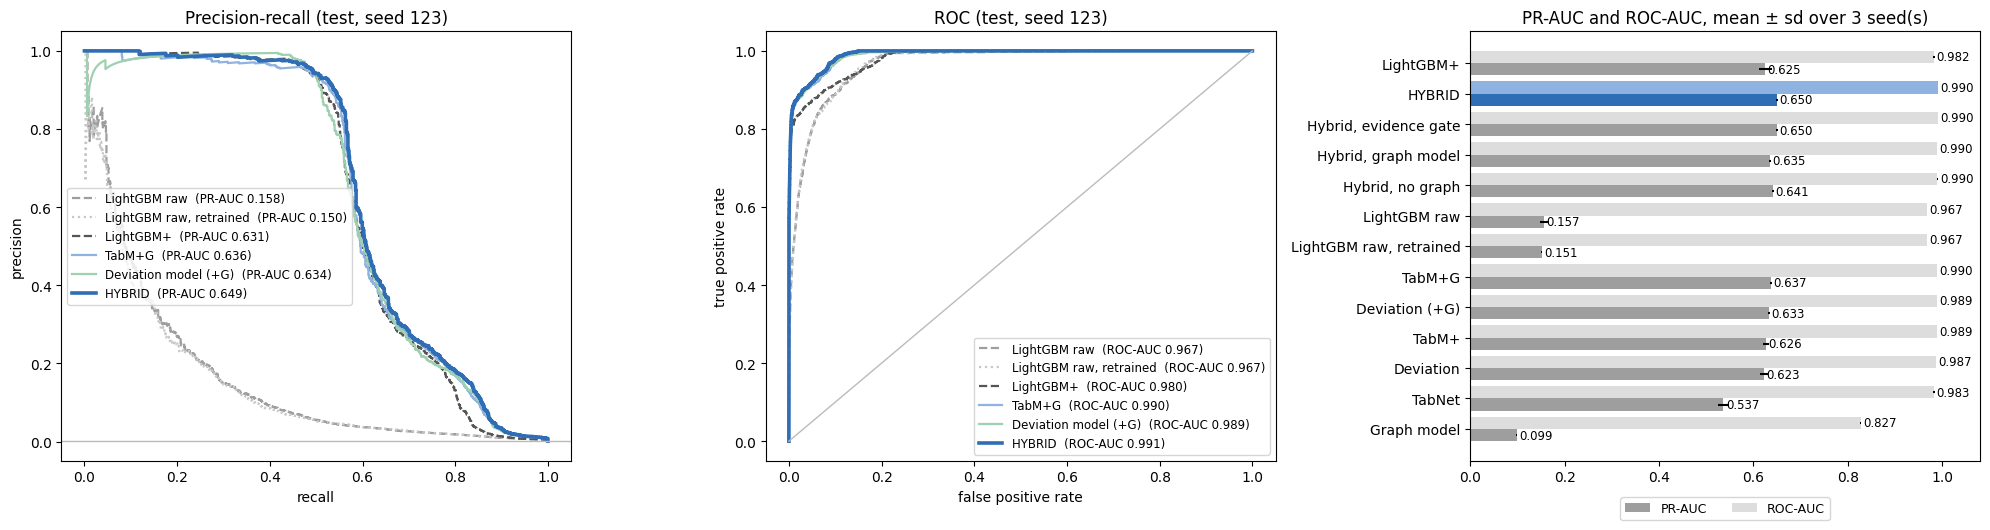

In [ ]:
# ── 22 · Figures: PR and ROC curves (seed SEED) + PR-AUC / ROC-AUC bars (all stored seeds). Needs only cell 1 ──
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve
y, split = np.load(P('y.npy')), np.load(P('split.npy')); te = split == 3; yt = y[te]
CURVES = [('lgb_raw', 'LightGBM raw', '#9e9e9e', '--'), ('lgb_rt', 'LightGBM raw, retrained', '#c7c7c7', ':'),
          ('lgb_g', 'LightGBM+', '#555555', '--'), ('tabpg', 'TabM+G', '#8fb3e0', '-'),
          ('devg', 'Deviation model (+G)', '#9fd1b0', '-'), ('hyb', 'HYBRID', '#2f6db5', '-')]
fig, ax = plt.subplots(1, 3, figsize=(20, 5.4))
for key, name, c, ls in CURVES:
    if not has_score(key): continue
    p = score(key)[te]; ok = ~np.isnan(p); pr, rc, _ = precision_recall_curve(yt[ok], p[ok]); fp, tp, _ = roc_curve(yt[ok], p[ok])
    lw = 2.6 if key == 'hyb' else 1.6
    ax[0].plot(rc, pr, c=c, ls=ls, lw=lw, label=f'{name}  (PR-AUC {ap(yt[ok], p[ok]):.3f})')
    ax[1].plot(fp, tp, c=c, ls=ls, lw=lw, label=f'{name}  (ROC-AUC {auc(yt[ok], p[ok]):.3f})')
ax[0].axhline(yt.mean(), c='#bbbbbb', lw=1); ax[0].set(title=f'Precision-recall (test, seed {SEED})', xlabel='recall', ylabel='precision'); ax[0].legend(fontsize=8.5)
ax[1].plot([0, 1], [0, 1], c='#bbbbbb', lw=1); ax[1].set(title=f'ROC (test, seed {SEED})', xlabel='false positive rate', ylabel='true positive rate'); ax[1].legend(fontsize=8.5, loc='lower right')
M = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + 'seed_*_metrics.csv')))])
order = [k for k in ['gnn', 'tabnet', 'dev', 'tabp', 'devg', 'tabpg', 'lgb_rt', 'lgb_raw', 'hyb_nog', 'hyb_gexp', 'hyb_gate', 'hyb', 'lgb_g'] if k in M.model.values]
lab = {'gnn': 'Graph model', 'hyb_gate': 'Hybrid, evidence gate', 'tabnet': 'TabNet', 'dev': 'Deviation', 'tabp': 'TabM+', 'devg': 'Deviation (+G)', 'tabpg': 'TabM+G',
       'lgb_rt': 'LightGBM raw, retrained', 'lgb_raw': 'LightGBM raw', 'hyb_nog': 'Hybrid, no graph', 'hyb_gexp': 'Hybrid, graph model',
       'hyb': 'HYBRID', 'lgb_g': 'LightGBM+'}
s = M.groupby('model')[['pr', 'roc']].agg(['mean', 'std']).reindex(order); yy = np.arange(len(order))
ax[2].barh(yy - .2, s[('pr', 'mean')], .4, xerr=s[('pr', 'std')].fillna(0), color=['#2f6db5' if k == 'hyb' else '#9e9e9e' for k in order], label='PR-AUC')
ax[2].barh(yy + .2, s[('roc', 'mean')], .4, xerr=s[('roc', 'std')].fillna(0), color=['#8fb3e0' if k == 'hyb' else '#dddddd' for k in order], label='ROC-AUC')
for i, k in enumerate(order):
    ax[2].text(s.loc[k, ('pr', 'mean')] + .005, i - .2, f"{s.loc[k, ('pr', 'mean')]:.3f}", va='center', fontsize=8.5)
    ax[2].text(s.loc[k, ('roc', 'mean')] + .005, i + .2, f"{s.loc[k, ('roc', 'mean')]:.3f}", va='center', fontsize=8.5)
ax[2].set_yticks(yy, [lab[k] for k in order]); ax[2].set_xlim(0, 1.08); ax[2].legend(loc='upper center', bbox_to_anchor=(.5, -.07), ncol=2, fontsize=9)
ax[2].set_title(f'PR-AUC and ROC-AUC, mean ± sd over {M.seed.nunique()} seed(s)')
plt.tight_layout(); plt.savefig(P(STORE + 'results.png'), dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
# ── 23 · One block to copy back (the numbers for the method document) ──
M = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + 'seed_*_metrics.csv')))])
Qs = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(P(STORE + 'seed_*_questions.csv')))])
a = M.groupby('model')[['pr', 'roc', 'recall_1pct', 'pr_new', 'pr_few', 'pr_regular', 'train_min']].agg(['mean', 'std']).round(4)
a.columns = [f'{c}_{s}' for c, s in a.columns]
q = Qs.groupby(['section', 'question'], sort=False).agg(d_pr=('d_pr', 'mean'), pr_lo=('pr_lo', 'mean'), pr_hi=('pr_hi', 'mean'),
                                                         d_roc=('d_roc', 'mean'), n_seeds=('seed', 'nunique')).round(4)
print('SEEDS:', sorted(M.seed.unique().tolist())); print('\nMODELS'); print(a.to_csv()); print('COMPARISONS'); print(q.to_csv())
for kind in ['gate', 'calibration']:
    fs = sorted(glob.glob(P(STORE + f'seed_*_{kind}.csv')))
    if fs: print(kind.upper()); print(pd.concat([pd.read_csv(f) for f in fs]).to_csv(index=False))

SEEDS: [7, 42, 123]

MODELS
model,pr_mean,pr_std,roc_mean,roc_std,recall_1pct_mean,recall_1pct_std,pr_new_mean,pr_new_std,pr_few_mean,pr_few_std,pr_regular_mean,pr_regular_std,train_min_mean,train_min_std
dev,0.6226,0.0081,0.9871,0.0006,0.8418,0.0035,0.1549,0.0175,0.5858,0.003,0.6644,0.0106,9.941,0.654
devg,0.6327,0.0018,0.9891,0.0005,0.8517,0.0034,0.137,0.011,0.5938,0.0017,0.6709,0.0024,9.395,1.2956
gnn,0.0988,0.0012,0.8271,0.0011,0.2535,0.0061,0.1381,0.0025,0.143,0.0059,0.074,0.0028,8.7815,0.4189
hyb,0.6502,0.0027,0.9905,0.0003,0.8547,0.0023,0.1724,0.0176,0.5932,0.0062,0.699,0.0023,,
hyb_both,0.6448,0.0021,0.9902,0.0002,0.8547,0.0017,0.172,0.0117,0.5798,0.0062,0.698,0.0018,,
hyb_gate,0.6497,0.0014,0.9903,0.0003,0.8547,0.0034,0.166,0.0128,0.5952,0.0087,0.6964,0.0044,,
hyb_gexp,0.6352,0.0023,0.9896,0.0002,0.8477,0.0019,0.167,0.0076,0.5684,0.0053,0.6933,0.0014,,
hyb_nog,0.6407,0.0021,0.9898,0.0002,0.8495,0.0006,0.1584,0.0258,0.5796,0.006,0.6947,0.0013,,
hyb_tabnet,0.6231,0.0067,0.9876,0

In [ ]:
# ── Minority-class F1 (AML literature metric): threshold chosen on the stop split, applied to test ──
from sklearn.metrics import f1_score, precision_recall_curve
y, split = np.load(P('y.npy')), np.load(P('split.npy')); st, te = split == 1, split == 3; rows = []
for k in ['lgb_raw', 'lgb_plus', 'lgb_g', 'tabpg', 'devg', 'hyb', 'hyb_gate']:
    if not has_score(k): continue
    s = score(k); p, r, th = precision_recall_curve(y[st], s[st]); f = 2 * p * r / np.maximum(p + r, 1e-9)
    t = th[np.argmax(f[:-1])]; pred = (s[te] >= t).astype(int)
    rows.append({'model': k, 'stop F1 (threshold set here)': f[:-1].max(), 'test minority F1': f1_score(y[te], pred),
                 'test precision': (y[te][pred == 1]).mean() if pred.sum() else 0, 'test recall': pred[y[te] == 1].mean()})
display(pd.DataFrame(rows).set_index('model').round(4))

,stop F1 (threshold set here),test minority F1,test precision,test recall
model,,,,
lgb_raw,0.2522,0.2297,0.2787,0.1954
lgb_plus,0.6498,0.6685,0.8869,0.5364
lgb_g,0.6490,0.6519,0.9286,0.5022
tabpg,0.6458,0.6680,0.8944,0.5331
devg,0.6341,0.6482,0.8374,0.5287
hyb,0.6461,0.6747,0.8545,0.5574
hyb_gate,0.6435,0.6757,0.8739,0.5508
